# Tuần 13 — Phân tích Nhân quả (2/2): Thiết kế thí nghiệm và nghiên cứu quan sát

**UET.MAT1052 — Xác suất thống kê**

ThS. Hoàng Hữu Bách — BM. Khoa học & Kỹ thuật tính toán - Khoa Công nghệ Thông tin, VNU-UET

### Câu hỏi của buổi

Lớp buổi sáng học bằng website tương tác mới, lớp buổi tối học bằng tài liệu PDF. Sau hai tuần, lớp dùng website có điểm trung bình cao hơn.

Chênh lệch ấy có phải do định dạng tài liệu không? Có thể lớp sáng vốn học khá hơn, có thể giảng viên khác nhau, có thể buổi sáng người học tỉnh táo hơn. Ra đề thi khó hơn hay dễ hơn không sửa được vấn đề này. Tuần 12 hỏi “cần giả định gì để suy luận nhân quả”; tuần này hỏi: **nếu được chủ động thiết kế, ta nên bố trí so sánh thế nào**, và khi không thể gán ngẫu nhiên thì còn những cách nào?

### Sau buổi này, bạn làm được

- phân biệt hiệu lực nội tại và hiệu lực khái quát; nói được lấy mẫu ngẫu nhiên và gán ngẫu nhiên phục vụ trục nào;
- xác định đúng đơn vị thí nghiệm và đơn vị quan sát; giải thích vì sao đếm nhầm đơn vị gây kết luận sai;
- nêu bốn thành phần của một RCT và áp dụng nguyên tắc sai khác duy nhất để tìm lỗi thiết kế;
- phân biệt gán ngẫu nhiên hoàn toàn, theo khối và theo cụm; đếm số cách gán;
- chọn chỉ số đánh giá đúng mục tiêu trong thử nghiệm A/B;
- mô tả các thiết kế quan sát (thí nghiệm tự nhiên, đoàn hệ, bệnh chứng, ghép cặp, trước–sau, DiD) và giả định của chúng.

Nội dung đáp ứng **LLO13.1/CLO4** của đề cương.

### Cần nhớ từ các buổi trước

- **Kết quả tiềm năng và ATE** (Tuần 12). $\tau_i=Y_i(1)-Y_i(0)$; hiệu thô = ATT + chệch chọn.
- **Gán ngẫu nhiên** (Tuần 12, mục 6). Làm chệch chọn bằng 0 ở mức kỳ vọng, nhưng một lần gán vẫn có thể lệch.
- **Kiểm định ngẫu nhiên hóa** (Tuần 10). Gán lại nhãn **đúng theo thiết kế**: 12 cảm biến chia 6–6 có $\binom{12}6=924$ cách.
- **Ghép cặp** (Tuần 11). Hai phép đo trên cùng đơn vị không độc lập; phân tích dãy hiệu.
- **Phương sai của trung bình** (Tuần 09). $\mathrm{Var}(\bar X)=\sigma^2/n$ chỉ đúng khi các quan sát độc lập.

### Cách học notebook này

1. **Đọc** tình huống và phần giải tay.
2. **Đoán** kết quả trước khi chạy ô code hay mở đáp án.
3. **Chạy** ô bằng `Shift + Enter`.
4. **So sánh** kết quả với dự đoán; nếu khác, tìm xem mình đã hiểu sai ở bước nào.

Khối **Vì sao?** chứa chứng minh, có thể đọc sau. Ô có chú thích **Thử đổi** là chỗ bạn sửa tham số rồi chạy lại. Tên Ví dụ, Bài và Câu hỏi giữ đúng như slide để tiện đối chiếu.

**Thực hành vẽ:** [hướng dẫn Plotnine](./HUONG_DAN_PLOT.md). Mỗi hình có một đoạn “Đọc code vẽ” giải thích đúng các lệnh dùng ở hình đó, và một đoạn “Đọc hình” chỉ ra cần nhìn vào đâu.

## Lộ trình học

| Cách học | Nội dung cần làm |
|---|---|
| Học trên lớp | Mục 1–5 theo slide: hai loại hiệu lực, đơn vị thí nghiệm, RCT, ba cách gán ngẫu nhiên, A/B. |
| Tự luyện | Ví dụ 1–5, Câu hỏi 1–4, Bài tập 1–3; mục 6 về nghiên cứu quan sát. |
| Đọc sâu | Mục 7 (bổ sung theo đề cương): ghép cặp, trước–sau, DiD, chuỗi thời gian bị gián đoạn; các khối **Vì sao?** về hiệu ứng thiết kế của mẫu cụm và DiD. |

Chạy từ đầu bằng **Restart Kernel and Run All Cells** trước khi học, để mọi bảng và hình khớp với chữ trong bài.

### Đi đến các phần

[1. Thiết kế cô lập được điều gì?](#muc-1) · [2. Một trường có 50 học sinh không tạo 50 lần gán](#muc-2) · [3. RCT cần đối chứng, biến kết quả và quy trình đo chung](#muc-3) · [4. Gán hoàn toàn, theo khối và theo cụm](#muc-4) · [5. A/B phải đo đúng mục tiêu](#muc-5) · [6. Khi không gán ngẫu nhiên được](#muc-6) · [7. Bổ sung theo đề cương: đơn vị tương tự, nhiễu ẩn và thời gian](#muc-7)

## Ký hiệu dùng trong buổi này

| Ký hiệu | Đọc là | Nghĩa | Ví dụ trong bài |
|---|---|---|---|
| Đơn vị thí nghiệm |  | cấp nhỏ nhất được gán nghiệm thức một cách độc lập | trường; chuồng gà |
| Đơn vị quan sát |  | cấp mà kết quả được đo | học sinh; từng con gà |
| Nghiệm thức / đối chứng | treatment / control | điều kiện đang thử / mốc so sánh | website / PDF |
| Khối | block | nhóm đơn vị giống nhau về một biến nền; gán ngẫu nhiên **trong** mỗi khối | khối GPA thấp, trung bình, cao |
| Cụm | cluster | nhóm đơn vị **cùng nhận** một nghiệm thức | cả một lớp, một trường |
| RCT | randomized controlled trial | thử nghiệm ngẫu nhiên có đối chứng | A/B testing là một RCT |
| Đoàn hệ / bệnh chứng | cohort / case-control | chọn theo phơi nhiễm rồi theo dõi / chọn theo kết cục rồi truy ngược | hút thuốc và ung thư phổi |
| DiD | khác biệt trong khác biệt | thay đổi ở nhóm can thiệp trừ thay đổi ở nhóm đối chứng | $-16-(-12)=-4$ |
| ITS | chuỗi thời gian bị gián đoạn | nhiều kỳ đo trước và sau một mốc can thiệp | lượng bán 12 kỳ |
| $\binom nk$ | tổ hợp chập k của n | số cách chọn $k$ đơn vị vào nhóm nghiệm thức | $\binom63=20$ |

Tuần này chủ yếu dùng **thuật ngữ** thay cho ký hiệu, nên bảng trên ghi thuật ngữ, tên tiếng Anh (cột "Đọc là") và ví dụ.

### Thiết lập tính toán

- `numpy`, `pandas`, `scipy.stats` như các tuần trước; `stats.ttest_ind` dùng trong mô phỏng mẫu cụm.
- `itertools.combinations` và `math.comb`: liệt kê và đếm số cách gán.
- `scipy.optimize.linear_sum_assignment`: ghép cặp tối ưu ở mục 7; `statsmodels.formula.api` (`smf`): hồi quy cho phần chuỗi thời gian.
- `DATA = Path('datasets')`: chứa `grad_job.csv` (mục 7) và `checkout_prepost.csv` (bốn siêu thị).
- Hầu hết hình trong tuần là **mô phỏng** hoặc sơ đồ minh họa; chú thích ngay tại chỗ.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display

DATA = Path('datasets')
assert DATA.is_dir(), 'Hãy mở notebook từ thư mục có datasets/ đi kèm.'
rng = np.random.default_rng(42)
pd.set_option('display.precision', 5)
pd.set_option('display.max_columns', 12)

from plotnine import (ggplot, aes, geom_histogram, geom_line, geom_point, geom_col,
    geom_vline, geom_hline, geom_segment, geom_area, geom_tile, geom_text,
    facet_wrap, labs, theme_minimal, theme, element_text, scale_color_manual,
    scale_fill_manual, coord_cartesian)

**Đối chiếu đề cương.** Mục 1–6 đi theo slide tuần 13 và giữ đủ bài tập gốc. Mục 7 bổ sung ghép cặp, trước–sau, DiD và chuỗi thời gian bị gián đoạn để đáp ứng mục 4.4–4.5 của đề cương; các ô này có đánh dấu `supplementary` trong metadata.

<a id="muc-1"></a>

## 1. Thiết kế cô lập được điều gì?

### Vì sao không chỉ so sánh dữ liệu sẵn có?

Trong tình huống mở đầu, lớp sáng và lớp tối khác nhau **cùng lúc** ở nhiều mặt: tài liệu, học sinh, giảng viên, giờ học. Không có cách nào, chỉ từ điểm thi, tách riêng phần chênh lệch do tài liệu. Muốn rút kết luận nhân quả phải **bố trí** can thiệp từ trước để các yếu tố khác không khác nhau có hệ thống giữa hai nhóm.

### Hai loại hiệu lực

- **Hiệu lực nội tại** (internal validity): phép so sánh trong nghiên cứu có **cô lập đúng** tác động của can thiệp không, tức đã loại trừ được các cách giải thích khác chưa?
- **Hiệu lực khái quát** (external validity): kết luận có còn đúng khi áp dụng **ngoài** mẫu và bối cảnh nghiên cứu không?

Hai loại không tự đi cùng nhau. Thử hợp kim trong phòng thí nghiệm (nhiệt độ, độ ẩm, tải trọng kiểm soát chặt) thường có hiệu lực nội tại cao, nhưng điều kiện lab có thể khác ngoài thực tế. Triển khai một thuật toán trên toàn bộ robot đang vận hành thì gần thực tế hơn, nhưng nhiều thứ thay đổi cùng lúc. "Kết luận nào chắc hơn" phải hỏi lại: chắc hơn **về điều gì**.

### Lấy mẫu ngẫu nhiên và gán ngẫu nhiên

| | Lấy mẫu ngẫu nhiên | Gán ngẫu nhiên |
|---|---|---|
| Làm gì | chọn đơn vị **từ tổng thể** bằng cơ chế xác suất (Tuần 09) | chia đơn vị **đã tuyển** vào các nhóm bằng cơ chế xác suất (Tuần 12) |
| Phục vụ | hiệu lực khái quát | hiệu lực nội tại |
| Không có thì | kết luận chỉ áp dụng cho nhóm đã tuyển | hai nhóm có thể khác nhau sẵn, gây nhiễu |

Có thể gán ngẫu nhiên nghiêm ngặt trên một mẫu thuận tiện (chỉ tình nguyện viên của một trường): nội tại cao, khái quát thấp. Dù có cả hai, nghiên cứu vẫn cần đo đúng, người tham gia tuân thủ, xử lý người bỏ cuộc, và nói rõ phạm vi áp dụng.

### Ví dụ 1 — Thử nghiệm hợp kim mới

Công thức hợp kim mới được thử trên một lô sản xuất, công thức cũ trên một lô khác. Hai lô được nung ở hai lò khác nhau, với tốc độ làm nguội khác nhau. Nếu lô công thức mới bền hơn, có thể quy toàn bộ chênh lệch cho công thức không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

Không. Ba thứ thay đổi cùng lúc: công thức, lò nung, tốc độ làm nguội. Lô mới bền hơn có thể do lò tốt hơn hoặc nguội chậm hơn.

Cách sửa: dùng cùng một lò và cùng tốc độ làm nguội cho cả hai công thức; hoặc chia mỗi lò thành nhiều mẻ và gán ngẫu nhiên công thức cho từng mẻ. Nếu muốn biết cả tác động của lò, dùng thiết kế nhiều yếu tố (thử mọi tổ hợp công thức × lò).

</details>

### Câu hỏi 1 — So sánh ba phương án nghiên cứu

A: 20 bệnh nhân tình nguyện tại một bệnh viện, gán ngẫu nhiên nghiêm ngặt vào 2 nhóm, theo dõi trong phòng bệnh kiểm soát chặt. B: khảo sát 5.000 người chọn ngẫu nhiên toàn quốc, không có nhóm đối chứng. C: chọn mẫu ngẫu nhiên toàn quốc, rồi gán ngẫu nhiên các đơn vị đã chọn vào 2 nhóm. Phương án nào có cả hai loại hiệu lực cao? Vì sao hai phương án còn lại không đạt cả hai?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*A:* nội tại cao (gán ngẫu nhiên), khái quát thấp (20 người tình nguyện ở một bệnh viện có thể khác bệnh nhân nói chung).

*B:* khái quát tốt cho việc **mô tả** tổng thể (mẫu ngẫu nhiên toàn quốc), nhưng nội tại kém cho câu hỏi tác động: không có đối chứng, không có cách nào biết điều gì xảy ra nếu không can thiệp.

*C:* đạt cả hai, vì kết hợp lấy mẫu ngẫu nhiên (khái quát) và gán ngẫu nhiên (nội tại).

Đây là so sánh trên **thiết kế** theo giả định của đề. Một phương án C thực hiện kém (nhiều người bỏ cuộc, đo không chuẩn) vẫn có thể cho kết luận sai.

</details>

Hình của slide (trang 16) đặt ba phương án lên hai trục. Ô dưới chỉ lập bảng tọa độ **minh họa**.

In [2]:
validity=pd.DataFrame({'design':['A: tình nguyện + gán','B: mẫu rộng, thiếu đối chứng','C: mẫu + gán ngẫu nhiên'],
    'external':[.2,.85,.85],'internal':[.85,.2,.85]})

<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(validity, aes(...))` lấy bảng `validity`; trong `aes`, trục ngang là cột `external`, trục đứng là cột `internal`. `color='design'` cho mỗi giá trị của cột `design` một màu riêng. `geom_point()` vẽ mỗi dòng của bảng thành một chấm.

**Đọc hình.** A ở góc trên trái (nội tại cao, khái quát thấp), B ở góc dưới phải, chỉ C ở góc trên phải. Hai trục vuông góc: đi lên theo một trục không tự kéo theo trục kia.

<!-- branch-plot-instructions: end -->

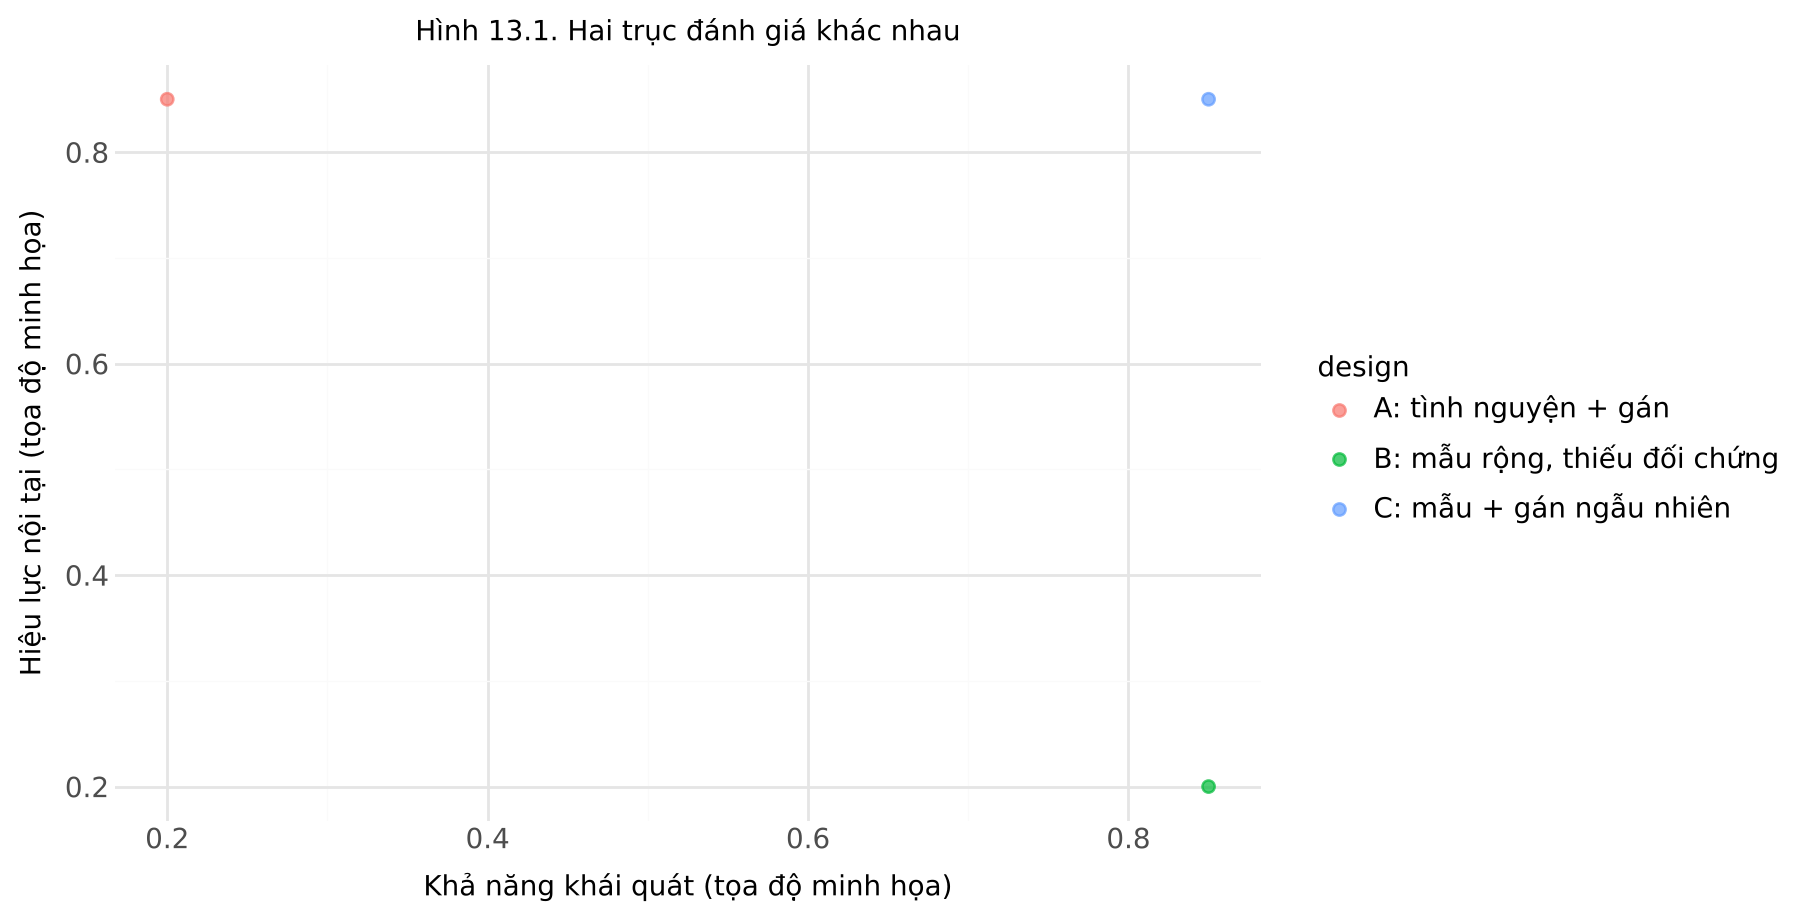

In [3]:
p = (ggplot(validity, aes(x='external', y='internal', color='design'))
     + geom_point(alpha=0.7, size=2)
     + labs(title='Hình 13.1. Hai trục đánh giá khác nhau', x='Khả năng khái quát (tọa độ minh họa)', y='Hiệu lực nội tại (tọa độ minh họa)')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

Các tọa độ chỉ để xếp ba phương án lên sơ đồ, không phải điểm số hay xác suất đo được.

<a id="muc-2"></a>

## 2. Một trường có 50 học sinh không tạo 50 lần gán

### Tình huống

Một chương trình đọc hiểu mới áp dụng cho **cả trường**, không cho từng học sinh. 8 trường tham gia: 4 trường dùng chương trình mới, 4 trường dùng cách dạy hiện hành. Mỗi trường có khoảng 50 học sinh, tổng cộng 400 học sinh. Số lần lặp độc lập của thí nghiệm này là 8 hay 400?

### Hai cấp đơn vị

- **Đơn vị thí nghiệm**: cấp nhỏ nhất được gán nghiệm thức một cách độc lập. Ở đây là **trường**.
- **Đơn vị quan sát**: cấp mà kết quả được đo. Ở đây là **học sinh**.

Số lần lặp độc lập là **8**. Học sinh cùng trường chịu chung một nghiệm thức, cùng giáo viên, cùng môi trường; điểm của họ có xu hướng giống nhau hơn điểm của học sinh hai trường khác nhau.

### Vì sao đếm nhầm đơn vị nguy hiểm?

Nếu coi các phép đo phụ thuộc nhau là các lần lặp độc lập, cỡ mẫu bị **thổi phồng giả tạo**. Sai số chuẩn tính ra nhỏ hơn thực tế, nên dễ ra giá trị p nhỏ khi không có tác động gì: **dương tính giả**.

Cùng lý do: một sinh viên làm 3 bài kiểm tra vẫn là **một** đơn vị, không phải ba.

### Khung thời gian đo

- **Cắt ngang**: đo kết quả một lần, sau khi can thiệp kết thúc.
- **Dọc** (dữ liệu bảng, panel): đo lặp lại nhiều thời điểm trên cùng đơn vị, trước và sau can thiệp. Cần lưu mã đơn vị và thời điểm; phương pháp DiD ở mục 7 cần loại dữ liệu này.
<details><summary><b>Vì sao?</b> mẫu cụm chứa ít thông tin hơn số dòng của nó</summary>

Mô hình: điểm học sinh $j$ ở trường $s$ là $Y_{sj}=70+u_s+e_{sj}$, với $u_s\sim\mathcal N(0,\sigma_u^2)$ là mức nền của trường và $e_{sj}\sim\mathcal N(0,\sigma_e^2)$ là phần riêng của học sinh, tất cả độc lập.

Trung bình của một trường gồm $m$ học sinh: $\bar Y_s=70+u_s+\bar e_s$, nên
$$\mathrm{Var}(\bar Y_s)=\sigma_u^2+\frac{\sigma_e^2}m.$$
Phần $\sigma_u^2$ **không giảm** khi thêm học sinh vào trường, vì mọi học sinh trong trường chia sẻ cùng một $u_s$.

So với giả định "400 học sinh độc lập", phương sai thật của trung bình nhóm lớn hơn khoảng **hiệu ứng thiết kế**
$$\text{DE}=1+(m-1)\rho,\qquad \rho=\frac{\sigma_u^2}{\sigma_u^2+\sigma_e^2},$$
với $\rho$ là tương quan nội cụm (hai học sinh cùng trường giống nhau đến đâu).

Với mô phỏng bên dưới, $\sigma_u=5$, $\sigma_e=10$, $m=50$: $\rho=25/125=0{,}2$ và $\text{DE}=1+49\times0{,}2=10{,}8$. SE thật lớn hơn SE "ngây thơ" khoảng $\sqrt{10{,}8}\approx3{,}3$ lần. Phân tích 400 học sinh như độc lập vì vậy tính $t$ lớn gấp khoảng 3,3 lần giá trị đúng. Về lượng thông tin, 400 học sinh ở đây chỉ tương đương khoảng $400/10{,}8\approx37$ học sinh độc lập.

</details>

### Ví dụ 2 — Thí nghiệm khẩu phần ăn cho gà

Thí nghiệm khẩu phần ăn mới: 6 chuồng gà, mỗi chuồng 50 con; gán 3 chuồng vào khẩu phần mới, 3 chuồng vào khẩu phần cũ. Cân từng con gà để đo khối lượng cuối kỳ. Xác định đơn vị thí nghiệm, đơn vị quan sát và số lần lặp độc lập.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Đơn vị thí nghiệm:* chuồng, vì khẩu phần được gán theo chuồng.

*Đơn vị quan sát:* từng con gà.

*Số lần lặp độc lập:* **6** (số chuồng), không phải 300. Gà trong cùng chuồng ăn chung khẩu phần, chịu chung nhiệt độ, ánh sáng, người chăm.

Tăng số gà mỗi chuồng từ 50 lên 100 gần như không giúp gì; muốn thí nghiệm chắc chắn hơn cần **thêm chuồng**.

</details>

### Câu hỏi 2 — Đơn vị thí nghiệm và số cách gán

Một công ty phần mềm thử giao diện mới trên 6 nhóm làm việc, mỗi nhóm 8 người; cả nhóm dùng chung giao diện được gán. Gán ngẫu nhiên 3 nhóm vào giao diện mới, 3 nhóm vào giao diện cũ. (a) Đơn vị thí nghiệm là gì? Số lần lặp độc lập là bao nhiêu? (b) Có bao nhiêu cách chia 6 nhóm thành 3 “mới” và 3 “cũ”?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*(a)* Đơn vị thí nghiệm là **nhóm làm việc**; đơn vị quan sát là từng người. Số lần lặp độc lập là **6**, không phải 48: người cùng nhóm dùng chung giao diện và làm việc với nhau.

*(b)*
$$\binom63=\frac{6!}{3!\,3!}=\frac{720}{6\times6}=20.$$
Nếu làm kiểm định ngẫu nhiên hóa như Tuần 10, phải gán lại **cả nhóm**, giữ 8 người của mỗi nhóm đi cùng nhau.

</details>

**Thí nghiệm: đếm nhầm đơn vị gây báo động giả.** Ô dưới mô phỏng lại hình của slide (trang 24). Chương trình **không có tác động gì**. Mỗi trường có mức nền riêng $u_s\sim\mathcal N(0,5^2)$, mỗi học sinh có thêm nhiễu riêng $\mathcal N(0,10^2)$. Lặp 1.200 thí nghiệm 8 trường × 50 học sinh; trong mỗi thí nghiệm, 4 trường đầu là nhóm "mới".

Mỗi thí nghiệm được phân tích theo hai cách:

- **Sai cấp**: kiểm định $t$ trên 200 học sinh "mới" và 200 học sinh "cũ" như 400 quan sát độc lập.
- **Đúng cấp**: tính điểm trung bình mỗi trường, rồi kiểm định $t$ trên 4 trung bình mỗi nhóm.

Bảng in ra tỉ lệ thí nghiệm bác bỏ $H_0$ ở mức 5%. Vì tác động thật bằng 0, mọi lần bác bỏ đều là sai lầm loại I.

**Bạn đoán trước:** cách sai cấp có giữ tỉ lệ báo động giả quanh 5% không?

In [4]:
r_cluster=np.random.default_rng(42)
B_cluster=1200
school_effect=r_cluster.normal(0,5,size=(B_cluster,8,1))
student_noise=r_cluster.normal(0,10,size=(B_cluster,8,50))
scores=70+school_effect+student_noise  # Không có tác động chương trình
# Với trường iid, đặt 4 trường đầu/4 cuối tương đương một gán 4–4.
naive_p=stats.ttest_ind(scores[:,:4,:].reshape(B_cluster,200),
    scores[:,4:,:].reshape(B_cluster,200),axis=1,equal_var=False).pvalue
school_means=scores.mean(axis=2)
correct_p=stats.ttest_ind(school_means[:,:4],school_means[:,4:],axis=1,equal_var=False).pvalue
false_positive=pd.DataFrame({'analysis':['Sai: 400 học sinh độc lập','Đúng cấp: 8 trường'],
    'rate':[(naive_p<.05).mean(),(correct_p<.05).mean()]})
display(false_positive)
one_trial=pd.DataFrame({'school':np.repeat(np.arange(1,9),50),'score':scores[0].ravel(),
    'group':np.repeat(['Mới']*4+['Cũ']*4,50)})

,analysis,rate
0,Sai: 400 học sinh độc lập,0.54917
1,Đúng cấp: 8 trường,0.03500


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(one_trial, aes(...))` lấy bảng `one_trial`; trong `aes`, trục ngang là cột `school`, trục đứng là cột `score`. `color='group'` cho mỗi giá trị của cột `group` một màu riêng. `geom_point()` vẽ mỗi dòng của bảng thành một chấm.

**Đọc hình.** Đây là **một** thí nghiệm trong 1.200. Mỗi cột chấm là 50 học sinh của một trường. Các cột không ngang nhau: mỗi trường có mức nền riêng, có trường quanh 75, có trường quanh 65, dù không có tác động chương trình nào. Chênh lệch giữa các cột là thứ mà phân tích 400 học sinh độc lập bỏ qua.

<!-- branch-plot-instructions: end -->

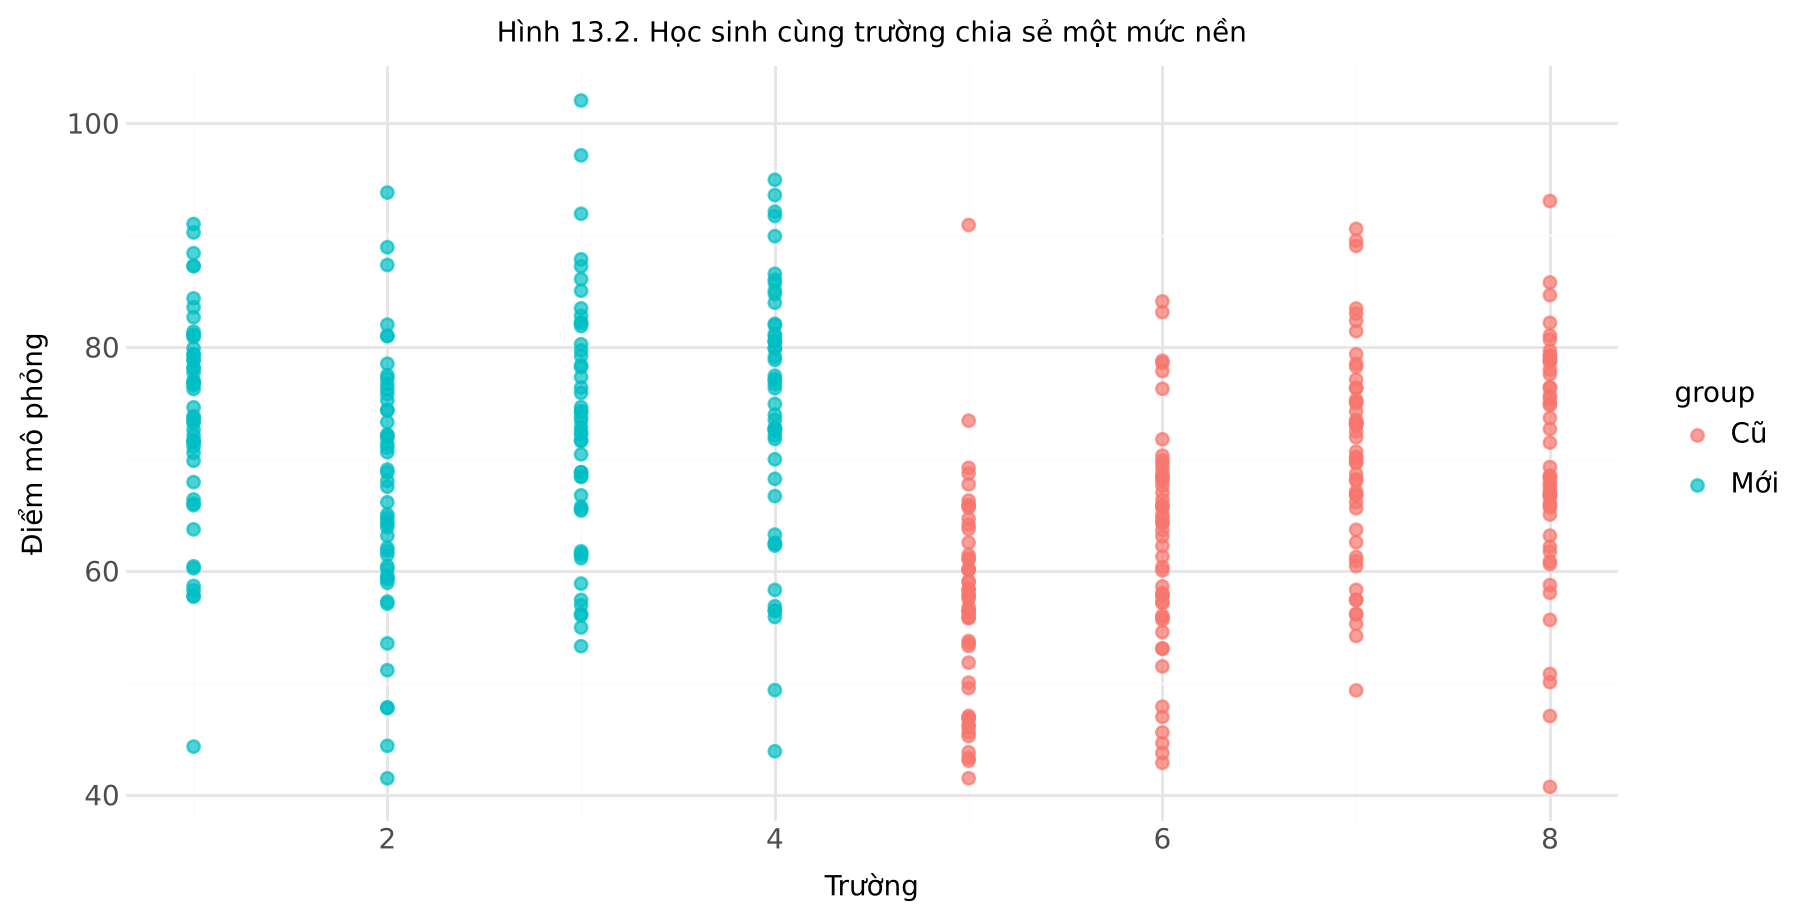

In [5]:
p = (ggplot(one_trial, aes(x='school', y='score', color='group'))
     + geom_point(alpha=0.7, size=2)
     + labs(title='Hình 13.2. Học sinh cùng trường chia sẻ một mức nền', x='Trường', y='Điểm mô phỏng')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(false_positive, aes(...))` lấy bảng `false_positive`; trong `aes`, trục ngang là cột `analysis`, trục đứng là cột `rate`. `geom_col()` vẽ cột có chiều cao lấy thẳng từ cột `y` đã tính sẵn trong bảng (không đếm lại); `position='dodge'` đặt các nhóm cạnh nhau.

**Đọc hình.** Cột trái là tỉ lệ báo động giả khi coi 400 học sinh là độc lập; cột phải là khi phân tích đúng ở cấp trường. Mức đúng phải là khoảng 0,05.

<!-- branch-plot-instructions: end -->

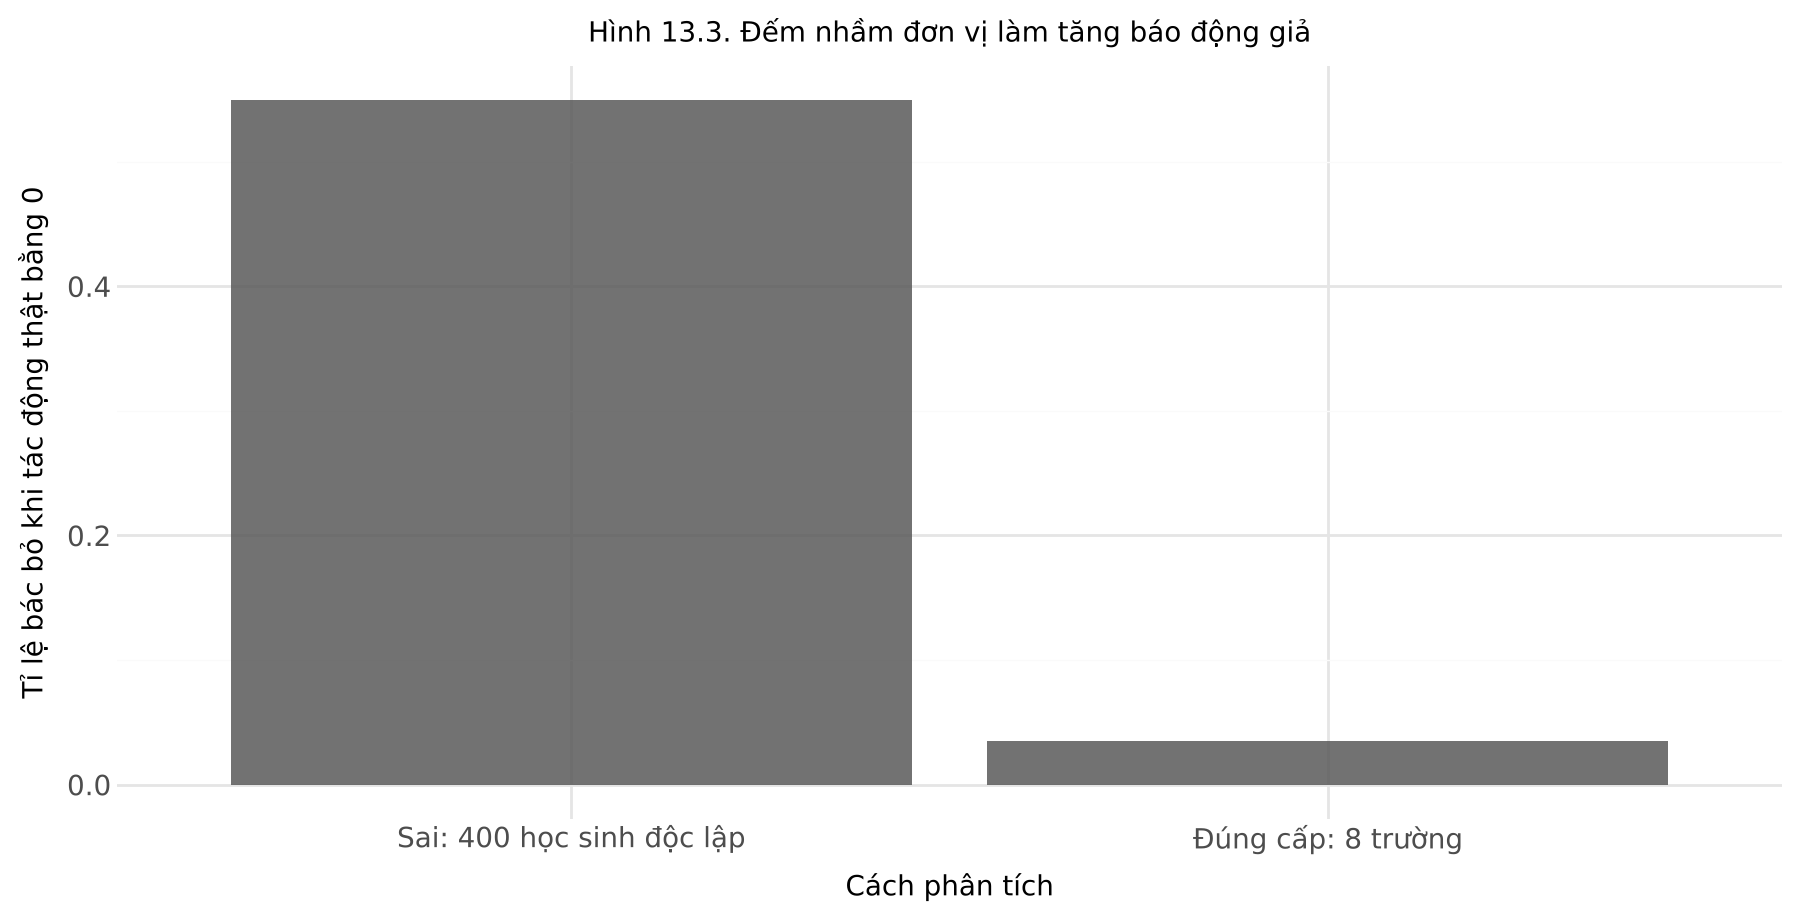

In [6]:
p = (ggplot(false_positive, aes(x='analysis', y='rate'))
     + geom_col(position='dodge', alpha=0.85)
     + labs(title='Hình 13.3. Đếm nhầm đơn vị làm tăng báo động giả', x='Cách phân tích', y='Tỉ lệ bác bỏ khi tác động thật bằng 0')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

**Kết quả.** Phân tích sai cấp bác bỏ $H_0$ trong khoảng 55% số thí nghiệm, dù chương trình không có tác động. Phân tích đúng cấp cho khoảng 3,5%, gần mức danh nghĩa 5%. Con số 55% khớp với slide và với khối **Vì sao?**: $t$ bị thổi phồng khoảng 3,3 lần.

Kiểm định $t$ trên 8 trung bình trường chỉ là xấp xỉ khi số trường nhỏ (đó là lý do tỉ lệ hơi dưới 5%). Một lựa chọn khác là kiểm định ngẫu nhiên hóa như Tuần 10: gán lại đúng 4–4 trên $\binom84=70$ cách chia trường.

<a id="muc-3"></a>

## 3. RCT cần đối chứng, biến kết quả và quy trình đo chung

### Bốn thành phần của một RCT

Thử nghiệm ngẫu nhiên có đối chứng (randomized controlled trial, RCT) là khung thiết kế chuẩn để suy luận nhân quả:

1. Chọn **biến kết quả** rõ ràng, xác định trước khi xem dữ liệu.
2. Lập **nhóm can thiệp** và **nhóm đối chứng**.
3. **Gán ngẫu nhiên** các đơn vị thí nghiệm vào các nhóm.
4. Thu thập kết quả theo **cùng một quy trình** cho mọi nhóm.

### Ba thuật ngữ

- **Nghiệm thức** (treatment): can thiệp hay điều kiện đang thử, do nhà nghiên cứu chủ động gán.
- **Đối chứng** (control): nhóm không nhận can thiệp mới (hoặc nhận điều kiện chuẩn hiện hành), dùng làm mốc trả lời câu hỏi "tốt hơn **so với điều gì**?".
- **Biến kết quả** (outcome): đại lượng được đo để đánh giá tác động; phải xác định và công bố trước khi thu dữ liệu, để không ai chọn cách đo có lợi sau khi đã thấy kết quả.

### Nguyên tắc sai khác duy nhất

Ngoài nghiệm thức, mọi điều kiện khác nên **giống nhau nhất có thể** giữa các nhóm. Nói gọn: chỉ yếu tố đang thử được quyền khác giữa các nhóm.

- Hợp kim: dùng cùng lò, cùng tốc độ làm nguội; chỉ công thức khác nhau.
- Website/PDF: nếu nhóm website được học thêm 30 phút, thời lượng đã thay đổi cùng lúc với định dạng. Khi đó thí nghiệm đo tác động của **cả gói** "website + 30 phút", không phải của riêng định dạng.

Không thể làm mọi đơn vị giống hệt nhau. Gán ngẫu nhiên lo phần còn lại: những khác biệt không kiểm soát được (sức khỏe, động lực, thói quen) sẽ **không khác có hệ thống** giữa hai nhóm, ở mức kỳ vọng. Làm mù (người tham gia và người đo không biết ai ở nhóm nào) khi có thể sẽ giúp quy trình đo giống nhau thật sự.

### Ví dụ 3 — Website tương tác và tài liệu PDF

Một giảng viên muốn biết sinh viên học hiệu quả hơn khi đọc tài liệu trên website tương tác hay trên file PDF. Giảng viên chia lớp thành hai nhóm: một nhóm học bằng website trong 2 tuần, một nhóm học bằng PDF; nội dung, thời lượng, giảng viên giữ như nhau. Hết 2 tuần, cả hai nhóm làm chung một bài kiểm tra. Xác định nghiệm thức, đối chứng, biến kết quả. Thiết kế này đã là RCT chưa?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Nghiệm thức:* học bằng website mới.

*Đối chứng:* học bằng PDF, mốc để trả lời "website tốt hơn **so với cách làm hiện tại** không?".

*Biến kết quả:* điểm bài kiểm tra chung sau 2 tuần, chọn và công bố trước khi thí nghiệm bắt đầu.

*Đã là RCT chưa?* Đề chỉ nói "chia lớp thành hai nhóm". Cần thêm: chia **ngẫu nhiên** (bốc thăm, phần mềm), ở đúng cấp (từng sinh viên, nếu họ học riêng). Nếu giảng viên tự chọn ai dùng website, hoặc cho hai bàn đầu dùng website, thì chưa phải RCT.

</details>

### Bài tập 1 — Vi phạm nguyên tắc sai khác duy nhất

Thí nghiệm hàn kim loại: nhóm A dùng máy hàn mới và thợ hàn có 10 năm kinh nghiệm; nhóm B dùng máy hàn cũ và thợ hàn mới vào nghề 1 năm. Yếu tố nào thay đổi cùng lúc với nghiệm thức (loại máy hàn)? Nếu nhóm A có mối hàn tốt hơn, có thể quy hoàn toàn cho máy hàn mới không?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Yếu tố thay đổi cùng lúc:* kinh nghiệm thợ hàn (10 năm so với 1 năm). Đây là vi phạm nguyên tắc sai khác duy nhất.

*Không thể quy hoàn toàn cho máy:* không tách được đóng góp của máy khỏi đóng góp của tay nghề.

*Cách sửa:* cho mỗi thợ hàn dùng cả hai máy theo thứ tự ngẫu nhiên; hoặc chia thợ theo kinh nghiệm thành các khối, rồi gán máy ngẫu nhiên trong mỗi khối (mục 4).

</details>

<a id="muc-4"></a>

## 4. Gán hoàn toàn, theo khối và theo cụm

### Ba cách gán nghiệm thức

- **Hoàn toàn**: chọn thẳng số đơn vị định trước cho mỗi nghiệm thức từ toàn bộ mẫu, không chia nhóm phụ trước.
- **Theo khối**: gộp các đơn vị giống nhau (theo GPA, theo khu vực) thành từng **khối**, rồi gán ngẫu nhiên **bên trong** mỗi khối. Giúp cân bằng những biến nền quan trọng đã biết trước.
- **Theo cụm**: gán **cả một cụm** (lớp, trường, chuồng) vào cùng một nghiệm thức. Bắt buộc khi can thiệp chỉ vận hành được ở cấp cụm (chương trình học áp dụng cho cả trường).

**Khối khác cụm.** Trong **mỗi khối** có cả hai nhóm nghiệm thức. **Mỗi cụm** chỉ thuộc một nhóm.

### Phân tích phải giữ thiết kế

| Thiết kế | Cấp gán | Khi phân tích |
|---|---|---|
| Khối | cá nhân, trong từng khối | giữ thông tin khối và số mỗi nhóm trong khối; nếu bỏ qua sẽ mất phần cân bằng mà khối tạo ra |
| Cụm | cả cụm | giữ cấu trúc lồng; các đơn vị trong cùng cụm không độc lập |

Bỏ qua cấu trúc khối hay cụm khi phân tích sẽ đánh giá sai độ chính xác, thường là quá lạc quan (mục 2 là ví dụ). Với kiểm định ngẫu nhiên hóa: gán lại theo khối không được phá số nhãn trong từng khối; gán lại theo cụm không được tráo nhãn từng cá thể.

### Ví dụ 4 — Bố trí khối theo GPA

Thí nghiệm website học tập: chia sinh viên thành các khối theo GPA ban đầu (cao, trung bình, thấp), rồi trong mỗi khối gán ngẫu nhiên vào website hoặc PDF. Lợi ích so với gán hoàn toàn là gì?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Lợi ích.* Bảo đảm cả hai nhóm có số sinh viên GPA cao, trung bình, thấp như nhau theo thiết kế; không để may rủi dồn nhiều sinh viên giỏi vào một nhóm. Khi GPA liên quan đến điểm thi, chênh lệch giữa hai nhóm vì vậy ít dao động hơn do phân bổ học lực, nên ước lượng tác động chính xác hơn.

*Giới hạn.* Cân bằng **mức** GPA (thấp/trung bình/cao) chưa chắc cân bằng chính xác GPA liên tục bên trong mỗi khối. Và khối chỉ cân bằng các biến dùng để chia khối; các biến khác vẫn nhờ gán ngẫu nhiên.

</details>

Ô dưới làm lại ví dụ của slide (trang 42–43) với 12 sinh viên, 4 người mỗi khối GPA, và tạo cả ba kiểu gán để vẽ Hình 3 của slide.

- Hàm `assign(ids)` nhận một danh sách mã, tạo nhãn nửa `website` nửa `pdf`, rồi xáo ngẫu nhiên bằng `r_assign.permutation`.
- `groupby('gpa_block')['id'].transform(assign)`: áp `assign` **riêng cho từng khối**, nên mỗi khối có đúng 2 website, 2 PDF.
- Gán hoàn toàn: áp `assign` cho cả 12 người một lần.
- Gán theo cụm: coi mỗi khối là một "lớp", chọn ngẫu nhiên 1 trong 3 lớp nhận website.

In [7]:
block_randomization_gpa=pd.DataFrame({'id':np.arange(1,13),
    'gpa_block':np.repeat(['low','mid','high'],4),'class':np.repeat([1,2,3],4)})
r_assign=np.random.default_rng(42)
def assign(ids):
    k=len(ids)//2
    return r_assign.permutation(['website']*k+['pdf']*(len(ids)-k))
blocked=block_randomization_gpa.copy()
blocked['group']=blocked.groupby('gpa_block',sort=False)['id'].transform(assign)
complete=block_randomization_gpa.copy();complete['group']=assign(complete.id)
clustered=block_randomization_gpa.copy()
selected_classes=r_assign.choice([1,2,3],1,replace=False)
clustered['group']=np.where(clustered['class'].isin(selected_classes),'website','pdf')
design_plot=pd.concat([d.assign(design=name) for d,name in
    [(complete,'Hoàn toàn (6–6)'),(blocked,'Trong khối (2–2 mỗi khối)'),(clustered,'Theo cụm (1 lớp/2 lớp)')]])
design_plot['column']=(design_plot.id-1)%4+1;design_plot['row']=(design_plot.id-1)//4+1
display(blocked)

,id,gpa_block,class,group
0,1,low,1,pdf
1,2,low,1,pdf
2,3,low,1,website
3,4,low,1,website
4,5,mid,2,pdf
5,6,mid,2,pdf
6,7,mid,2,website
7,8,mid,2,website
8,9,high,3,website
9,10,high,3,pdf


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(design_plot, aes(...))` lấy bảng `design_plot`; trong `aes`, trục ngang là cột `column`, trục đứng là cột `row`. `color='group'` cho mỗi giá trị của cột `group` một màu riêng. `geom_point()` vẽ mỗi dòng của bảng thành một chấm. `facet_wrap('~design', scales='free')` vẽ mỗi giá trị của `design` vào một ô riêng; `scales='free'` cho mỗi ô thang trục riêng, nên so các ô bằng số ghi trên trục, không bằng độ cao trên màn hình.

**Đọc hình.** Mỗi ô vẽ 12 sinh viên thành 3 hàng × 4 cột; hàng là khối GPA (cũng là “lớp” trong ví dụ cụm). Ô “Hoàn toàn”: 6 website, 6 PDF, nhưng một hàng có thể có 3 hoặc 1 website. Ô “Trong khối”: **mỗi hàng** đúng 2 website, 2 PDF. Ô “Theo cụm”: cả một hàng cùng màu.

<!-- branch-plot-instructions: end -->

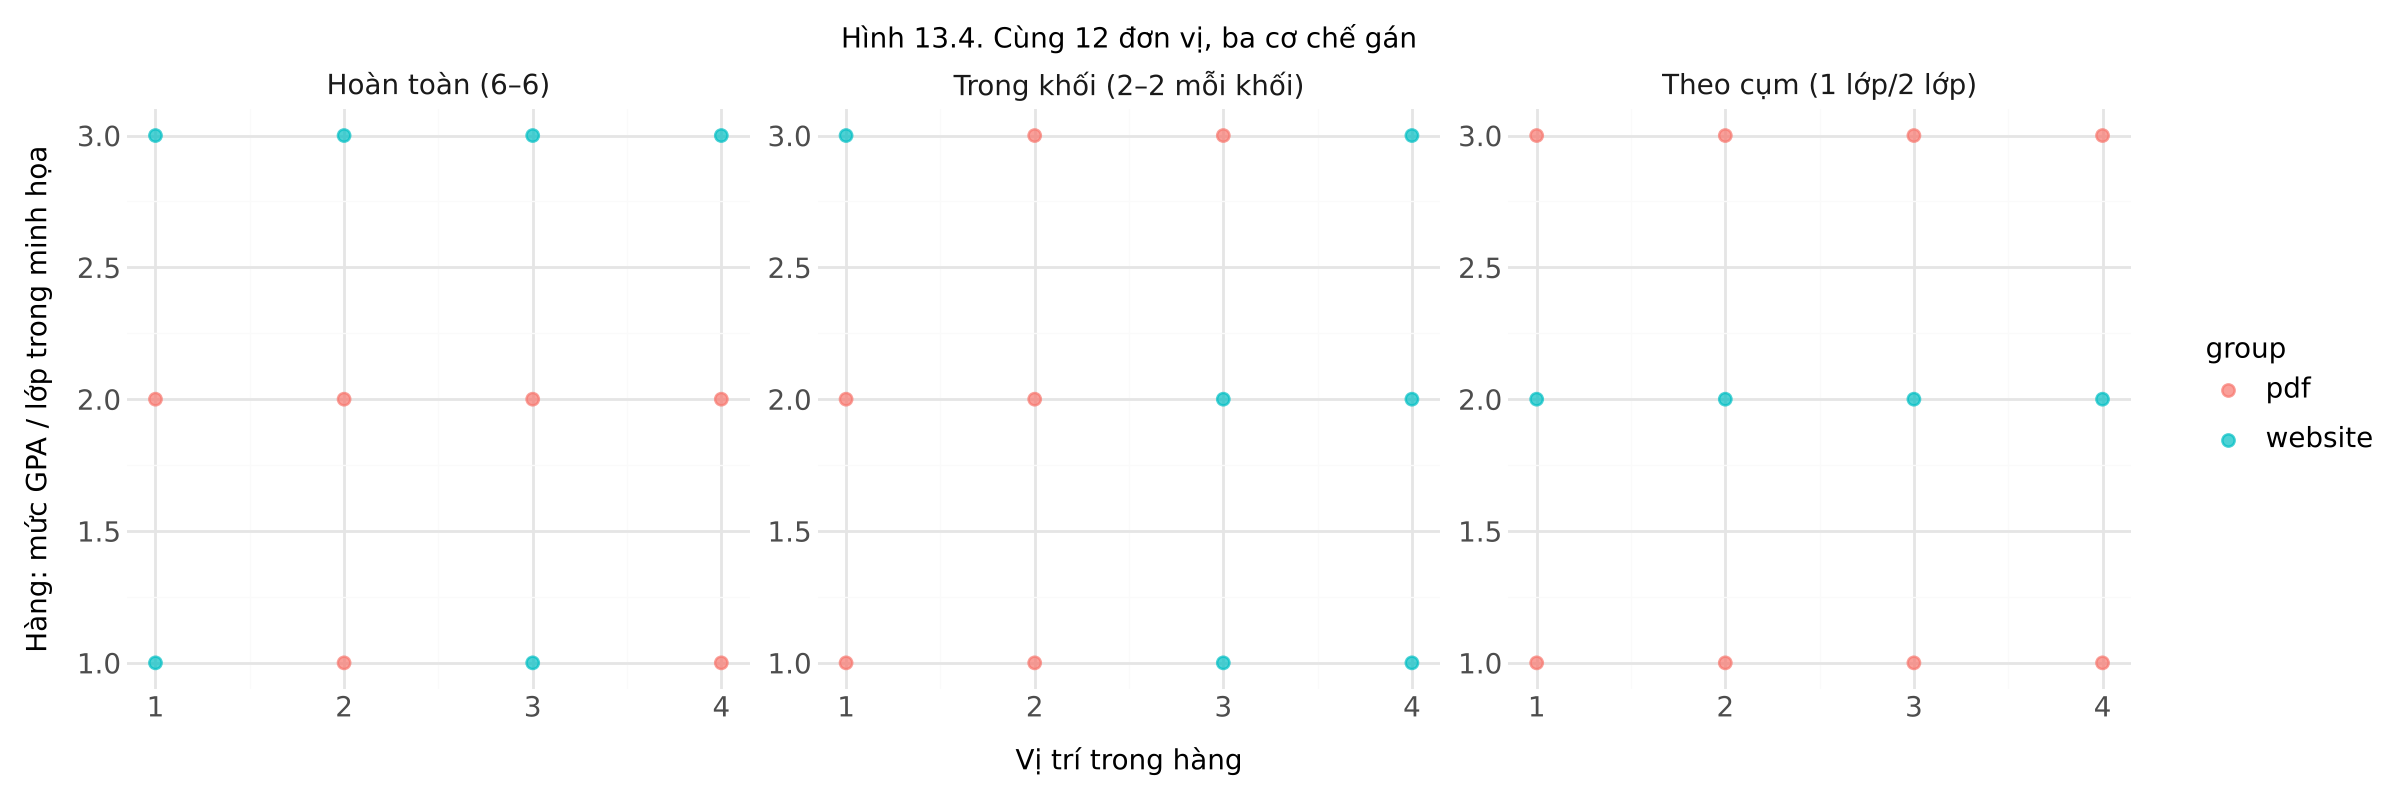

In [8]:
plot_data = design_plot.copy()
plot_data['design'] = pd.Categorical(plot_data['design'], categories=list(pd.unique(plot_data['design'])), ordered=True)
p = (ggplot(plot_data, aes(x='column', y='row', color='group'))
     + geom_point(alpha=0.7, size=2)
     + facet_wrap('~design', scales='free', ncol=3)
     + labs(title='Hình 13.4. Cùng 12 đơn vị, ba cơ chế gán', x='Vị trí trong hàng', y='Hàng: mức GPA / lớp trong minh họa')
     + theme_minimal()
     + theme(figure_size=(12, max(4, 3.4*int(np.ceil(design_plot['design'].nunique()/3)))), text=element_text(size=10)))
display(p)

Trong ví dụ cụm chỉ có 3 lớp, không chia đều được: 1 lớp nhận website, 2 lớp nhận PDF (4 so với 8 sinh viên). Gán theo cụm không giữ được 6–6 cá thể; đó là đặc điểm, không phải lỗi.

**Thí nghiệm: khối giảm dao động.** Hình của slide (trang 41) dùng 24 sinh viên, 8 người mỗi khối, GPA trung bình 2,3; 3,0; 3,7. Ô dưới lặp 10.000 lần mỗi kiểu gán (hoàn toàn 12–12; theo khối 4–4 trong mỗi khối) và ghi lại chênh lệch GPA trung bình **ban đầu** giữa nhóm website và nhóm PDF. Đây là chênh lệch trước can thiệp: lý tưởng là 0.

In [9]:
r_balance=np.random.default_rng(42)
gpa=np.r_[r_balance.normal(2.3,.12,8),r_balance.normal(3.,.12,8),r_balance.normal(3.7,.12,8)]
B_balance=10_000
full_diff=[];block_diff=[]
for _ in range(B_balance):
    idx=r_balance.choice(24,12,replace=False)
    full_diff.append(gpa[idx].mean()-np.delete(gpa,idx).mean())
    block_idx=np.concatenate([r_balance.choice(np.arange(k,k+8),4,replace=False) for k in [0,8,16]])
    block_diff.append(gpa[block_idx].mean()-np.delete(gpa,block_idx).mean())
balance_plot=pd.concat([pd.DataFrame({'difference':v,'design':name}) for name,v in
    [('Hoàn toàn',full_diff),('Theo khối GPA',block_diff)]])
display(balance_plot.groupby('design').difference.agg(['mean','std']))

,mean,std
design,,
Hoàn toàn,0.00177,0.25099
Theo khối GPA,0.00004,0.04136


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(balance_plot, aes(...))` lấy bảng `balance_plot`; trong `aes`, trục ngang là cột `difference`. `fill='design'` cho mỗi giá trị của cột `design` một màu riêng; `alpha=0.6` làm cột trong suốt để thấy phần chồng lên nhau. `geom_histogram(bins=30)` chia trục ngang thành 30 khoảng bằng nhau rồi đếm số dòng của bảng rơi vào mỗi khoảng; chiều cao cột là số đếm. `geom_vline(xintercept=...)` vẽ đường đứt đoạn tại `0`.

**Đọc hình.** Cả hai histogram có tâm ở 0: cả hai cách đều công bằng ở mức kỳ vọng. Histogram “Theo khối” hẹp hơn hẳn: gần như mọi phép gán cho chênh lệch dưới 0,1 điểm GPA; với gán hoàn toàn, chênh lệch 0,3–0,5 điểm không hiếm.

<!-- branch-plot-instructions: end -->

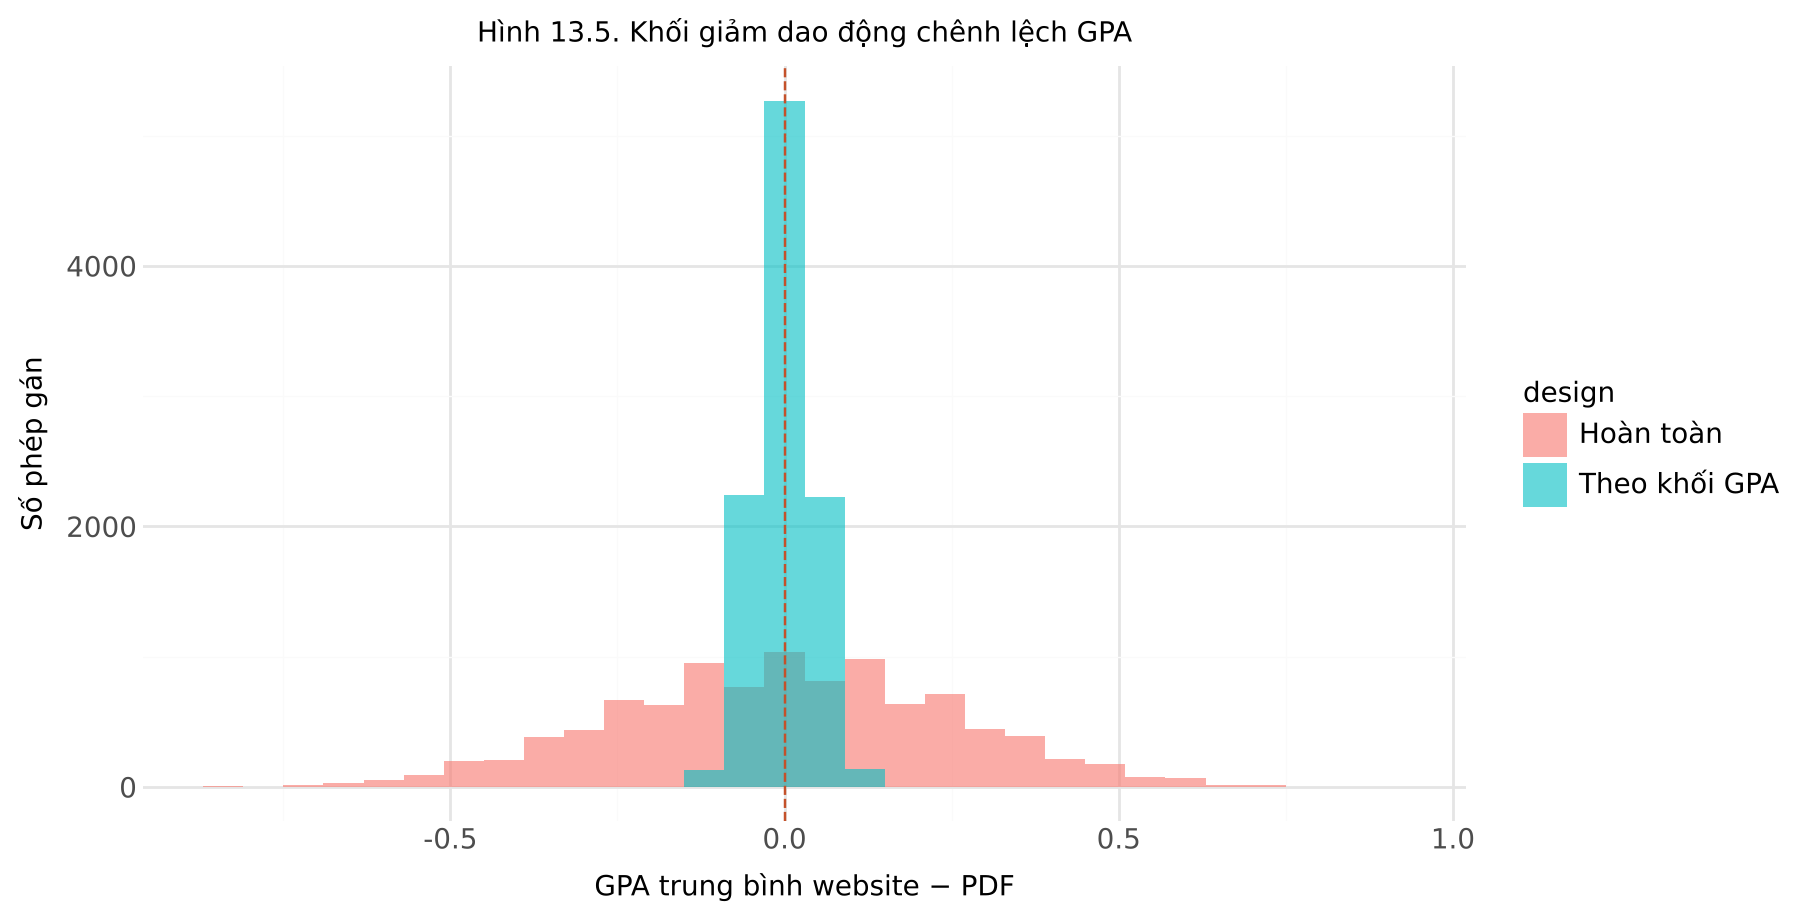

In [10]:
p = (ggplot(balance_plot, aes(x='difference', fill='design'))
     + geom_histogram(bins=30, alpha=0.6, position='identity')
     + geom_vline(xintercept=0, linetype='dashed', color='#C4512A')
     + labs(title='Hình 13.5. Khối giảm dao động chênh lệch GPA', x='GPA trung bình website − PDF', y='Số phép gán')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

**Kết quả.** Độ lệch chuẩn của chênh lệch GPA: khoảng 0,25 với gán hoàn toàn, 0,04 với gán theo khối, nhỏ hơn khoảng 6 lần. Khối chỉ còn để lại phần chênh lệch GPA **bên trong** từng khối, vốn rất nhỏ (SD 0,12).

Đây là lợi ích về **độ chính xác**. Nó không có nghĩa mọi biến nền khác đều cân bằng trong một lần gán theo khối.

### Ví dụ 5 — Kết hợp bố trí khối và cụm

Khu ruộng thử nghiệm giống lúa được chia theo địa hình thành hai khu: đất cao và đất thấp. Trong mỗi khu, gán ngẫu nhiên các thửa ruộng vào giống mới hoặc giống cũ. Xác định khối và cụm trong thiết kế này.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Khối:* khu địa hình (đất cao, đất thấp). Trong mỗi khối có cả thửa giống mới và thửa giống cũ.

*Cụm:* thửa ruộng. Giống được gán cho cả thửa; nếu đo năng suất trên nhiều khóm lúa trong một thửa, các khóm đó là đơn vị quan sát lồng trong cụm.

*Phân tích:* so giống mới và cũ **trong từng khu** rồi gộp lại; mỗi thửa đóng góp một giá trị (ví dụ năng suất trung bình của thửa), không đếm từng khóm như lần lặp độc lập.

</details>

### Câu hỏi 3 — Số cách chia trong một khối

Khối GPA cao gồm 4 sinh viên $\{9,10,11,12\}$. Chọn ngẫu nhiên 2 người vào nhóm website, 2 người còn lại vào PDF. (a) Có bao nhiêu cách chia trong khối này? (b) Nếu có thêm khối GPA thấp cũng 4 sinh viên, chia 2–2 độc lập với khối trên, tổng số cách gán của cả hai khối là bao nhiêu?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*(a)*
$$\binom42=\frac{4!}{2!\,2!}=6,$$
cụ thể nhóm website là $\{9,10\}$, $\{9,11\}$, $\{9,12\}$, $\{10,11\}$, $\{10,12\}$ hoặc $\{11,12\}$.

*(b)* Mỗi cách gán chung phải chọn **cả** một cách ở khối cao **và** một cách ở khối thấp. Theo quy tắc nhân (Tuần 06): $6\times6=36$ cách. Cộng $6+6=12$ là sai, vì đó là số cách chỉ chọn ở một trong hai khối.

So sánh: gán hoàn toàn 8 người thành 4–4 có $\binom84=70$ cách. Khối loại bỏ $70-36=34$ cách gán "lệch" (ví dụ 4 người GPA cao cùng vào website).

</details>

In [11]:
from math import comb
from itertools import combinations
print(list(combinations([9,10,11,12],2)))
print('6 nhóm chia 3–3:',comb(6,3),'; hai khối 4 chia 2–2:',comb(4,2)**2)

[(9, 10), (9, 11), (9, 12), (10, 11), (10, 12), (11, 12)]
6 nhóm chia 3–3: 20 ; hai khối 4 chia 2–2: 36


<a id="muc-5"></a>

## 5. A/B phải đo đúng mục tiêu

### A/B testing là một RCT

Một công ty thương mại điện tử gán ngẫu nhiên người dùng (thường bằng cách băm mã định danh) vào giao diện A hoặc B, rồi so sánh một **chỉ số đánh giá tổng thể** (ví dụ tỉ lệ hoàn tất đơn hàng) giữa hai nhóm. Mọi nguyên tắc của RCT áp dụng nguyên vẹn: đối chứng, sai khác duy nhất, gán ngẫu nhiên, biến kết quả định trước.

### Khác gì RCT truyền thống?

- Cỡ mẫu rất lớn, từ hàng nghìn đến hàng triệu người dùng.
- Chu kỳ ngắn, lặp lại liên tục.
- Phân tích tự động; nhiều thử nghiệm chạy song song.

Ba khác biệt này **không** thay đổi các nguyên tắc. Hai lưu ý thực hành:

- **Đơn vị là người dùng**, không phải lượt nhấp. Gán theo mã người dùng phải ổn định để một người không đổi nhóm giữa các lần truy cập. 1.000 lượt nhấp của 10 người không phải 1.000 lần lặp.
- **Nhìn kết quả nhiều lần, hoặc thử nhiều chỉ số rồi chọn cái đẹp nhất**, làm tăng xác suất báo động giả (Tuần 11, so sánh bội). Dữ liệu nhiều hơn không sửa được lỗi này.

### Bài tập 2 — Chọn sai chỉ số đánh giá

Thử nghiệm 2 giao diện trang thanh toán, dùng “tỉ lệ nhấp nút Mua” làm chỉ số đánh giá tổng thể. Giao diện B có tỉ lệ nhấp cao hơn nên được triển khai chính thức. Ba tuần sau, doanh thu thực tế của B lại thấp hơn A vì nhiều người nhấp Mua rồi bỏ giỏ hàng giữa chừng. Vấn đề nằm ở bước nào của thiết kế?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

Không phải lỗi thống kê: thí nghiệm gán ngẫu nhiên đúng, đọc kết quả đúng, B **thật sự** có tỉ lệ nhấp cao hơn.

Lỗi ở **bước chọn biến kết quả**. Tỉ lệ nhấp nút Mua không phản ánh mục tiêu thật (doanh thu, hay tỉ lệ hoàn tất đơn hàng). Một giao diện có thể làm người dùng nhấp nhiều hơn mà không mua nhiều hơn, ví dụ vì nút to hơn nhưng phí vận chuyển bị giấu đến bước sau.

Cách làm đúng: chọn chỉ số chính bám sát mục tiêu ngay từ đầu; có thể theo dõi thêm chỉ số phụ (tỉ lệ nhấp) như tín hiệu giám sát. Không được đổi chỉ số chính sau khi đã nhìn dữ liệu để tuyên bố một giao diện thắng.

</details>

Ô dưới lập bảng cho hình của slide (trang 55). Các giá trị được đọc từ hình minh họa, không phải dữ liệu người dùng thật.

In [12]:
ab_metrics=pd.DataFrame({'interface':['A','B','A','B'],
    'metric':['Tỉ lệ nhấp (%)']*2+['Doanh thu/người dùng']*2,'value':[12,18,52,41]})
# Các giá trị minh họa đọc từ hình slide, không phải dữ liệu người dùng thật.

<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(ab_metrics, aes(...))` lấy bảng `ab_metrics`; trong `aes`, trục ngang là cột `interface`, trục đứng là cột `value`. `geom_col()` vẽ cột có chiều cao lấy thẳng từ cột `y` đã tính sẵn trong bảng (không đếm lại); `position='dodge'` đặt các nhóm cạnh nhau. `facet_wrap('~metric', scales='free')` vẽ mỗi giá trị của `metric` vào một ô riêng; `scales='free'` cho mỗi ô thang trục riêng, nên so các ô bằng số ghi trên trục, không bằng độ cao trên màn hình.

**Đọc hình.** Ô “Tỉ lệ nhấp”: B cao hơn A (18% so với 12%). Ô “Doanh thu/người dùng”: A cao hơn B (52 so với 41). Hai ô có đơn vị khác nhau, nên chỉ so A với B **trong cùng một ô**.

<!-- branch-plot-instructions: end -->

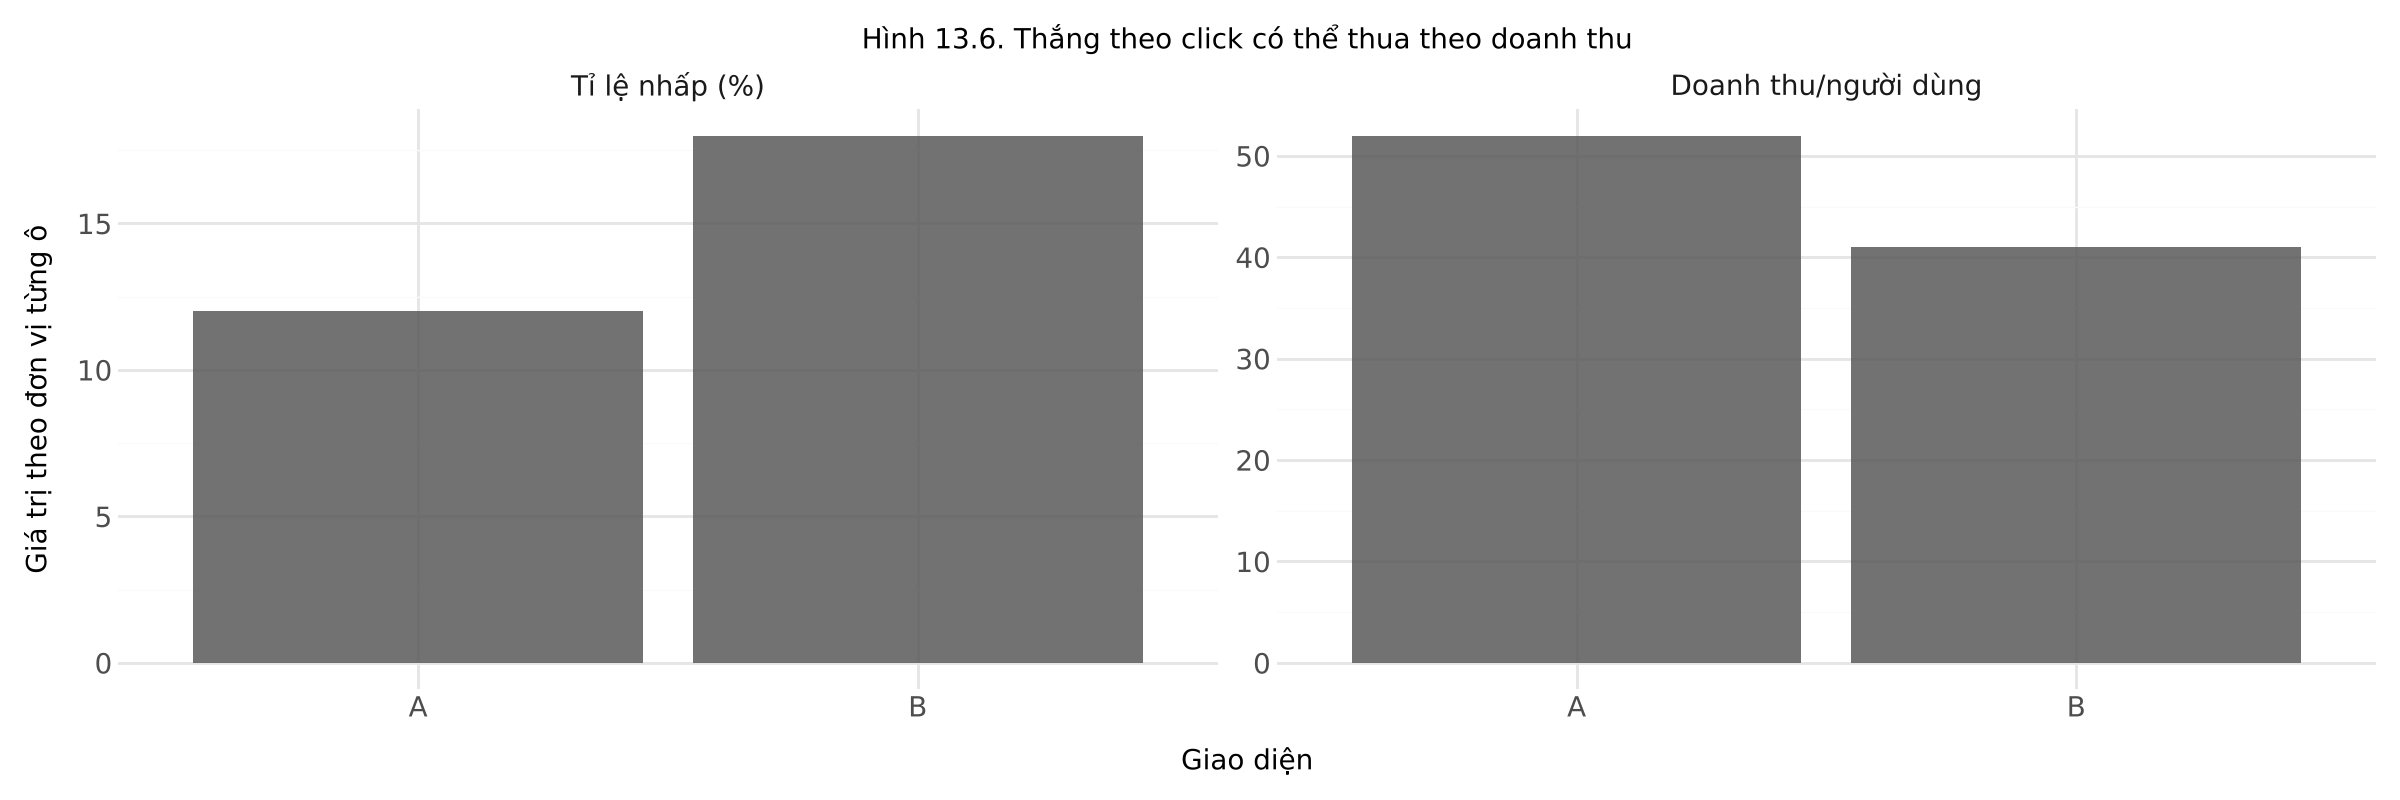

In [13]:
plot_data = ab_metrics.copy()
plot_data['metric'] = pd.Categorical(plot_data['metric'], categories=list(pd.unique(plot_data['metric'])), ordered=True)
p = (ggplot(plot_data, aes(x='interface', y='value'))
     + geom_col(position='dodge', alpha=0.85)
     + facet_wrap('~metric', scales='free', ncol=3)
     + labs(title='Hình 13.6. Thắng theo click có thể thua theo doanh thu', x='Giao diện', y='Giá trị theo đơn vị từng ô')
     + theme_minimal()
     + theme(figure_size=(12, max(4, 3.4*int(np.ceil(ab_metrics['metric'].nunique()/3)))), text=element_text(size=10)))
display(p)

Chọn A hay B phụ thuộc hoàn toàn vào chỉ số nào được định trước là chỉ số chính. Nếu mục tiêu là doanh thu, A thắng dù thua ở tỉ lệ nhấp.

<a id="muc-6"></a>

## 6. Khi không gán ngẫu nhiên được

Nhiều câu hỏi nhân quả quan trọng không thể gán ngẫu nhiên, vì đạo đức hoặc vì thực tế: không ai gán ngẫu nhiên người hút thuốc, ruộng chịu hạn, hay công ty áp dụng chính sách mới. Khi đó dùng **thiết kế quan sát**.

### Ba thiết kế chính

- **Thí nghiệm tự nhiên**: một sự kiện bên ngoài (thay đổi chính sách, một ngưỡng hành chính) tạo ra sự phân nhóm gần như ngẫu nhiên. Ví dụ: tiêu chuẩn khí thải mới áp dụng từ một ngày cụ thể; xe sản xuất ngay trước và ngay sau ngày đó gần giống nhau, chỉ khác ở việc phải tuân thủ tiêu chuẩn. Phải **lập luận** vì sao cơ chế đó gần ngẫu nhiên; một mốc ngày không tự bảo đảm điều đó (có thể trùng mùa vụ, đổi nhà cung cấp...).
- **Đoàn hệ** (cohort): chọn người theo **phơi nhiễm** (ví dụ có hút thuốc hay không), rồi theo dõi xuôi thời gian để đo **kết cục** về sau.
- **Bệnh chứng** (case-control): chọn người theo **kết cục** đã xảy ra (đã mắc bệnh hay chưa), rồi truy ngược tình trạng **phơi nhiễm** trong quá khứ. Đặc biệt hiệu quả khi kết cục hiếm. Lưu ý: tỉ lệ người bệnh trong mẫu do nhà nghiên cứu chọn (ví dụ 50% ca, 50% chứng), nên không dùng trực tiếp làm nguy cơ mắc bệnh của tổng thể.

### Mức độ tin cậy

Biến gây nhiễu ảnh hưởng **cả** việc nhận phơi nhiễm **lẫn** kết quả, đúng như Tuần 12. Slide xếp mức tin cậy giảm dần: thí nghiệm tự nhiên (gần RCT) → đoàn hệ, bệnh chứng có kiểm soát tốt biến nền → so sánh quan sát thuần túy. Thứ bậc này là hướng dẫn chung; một thí nghiệm tự nhiên với cơ chế đáng ngờ có thể kém một nghiên cứu đoàn hệ đo kỹ. Nguyên tắc sai khác duy nhất không tự đúng trong dữ liệu quan sát; phải biện luận bằng hiểu biết về bối cảnh.

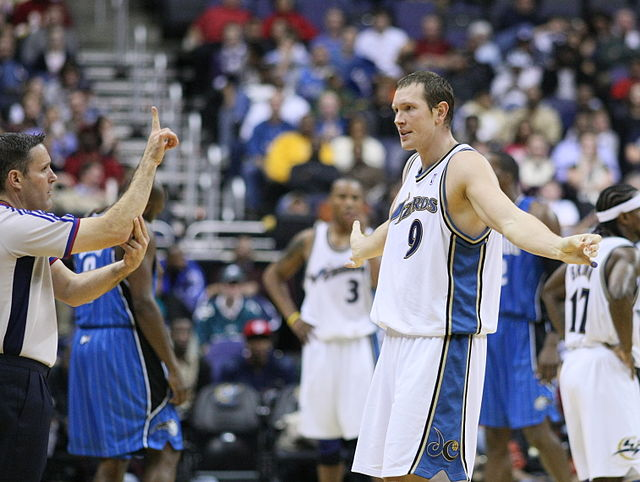

*Hình tham khảo 13.38: Bối cảnh bóng rổ trong ví dụ thí nghiệm tự nhiên của STAT 20. Nguồn: STAT 20 bản dịch tiếng Việt, mục 6.3, hình nhúng trong học liệu gốc.*

Mục 6.3 của STAT 20 dùng một ví dụ thể thao làm thí nghiệm tự nhiên. Muốn dùng được, phải lập luận rằng cơ chế phân nhóm gần ngẫu nhiên so với kết quả; chỉ nhìn ảnh hay một bảng tương quan thì chưa đủ.

Ô dưới lập bảng cho sơ đồ của slide (trang 60): mỗi thiết kế có hai bước trên trục thời gian (0 = quá khứ, 1 = thời điểm có kết cục). Cột `selection` đánh dấu bước được dùng để **chọn người vào mẫu**.

In [14]:
study_time=pd.DataFrame({'design':['Đoàn hệ','Đoàn hệ','Bệnh chứng','Bệnh chứng'],
    'time':[0,1,0,1],'stage':['Chọn theo phơi nhiễm','Theo dõi kết cục',
                            'Truy ngược phơi nhiễm','Chọn theo kết cục'],
    'selection':[1,0,0,1]})
display(study_time)

,design,time,stage,selection
0,Đoàn hệ,0,Chọn theo phơi nhiễm,1
1,Đoàn hệ,1,Theo dõi kết cục,0
2,Bệnh chứng,0,Truy ngược phơi nhiễm,0
3,Bệnh chứng,1,Chọn theo kết cục,1


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `aes('time', 'design', label='stage')`: trục ngang là thời gian, trục đứng là thiết kế, chữ là tên bước. `geom_point(aes(color='selection'))` tô điểm theo việc bước đó có dùng để chọn mẫu hay không; `geom_text(nudge_y=.18)` đặt chữ hơi cao hơn điểm; `geom_segment(..., inherit_aes=False)` vẽ đường thời gian nối hai bước của mỗi thiết kế.

**Đọc hình.** Đoàn hệ: điểm chọn mẫu ở **bên trái** (quá khứ), rồi đi xuôi đến kết cục. Bệnh chứng: điểm chọn mẫu ở **bên phải** (kết cục đã xảy ra), rồi nhìn ngược về quá khứ.

<!-- branch-plot-instructions: end -->

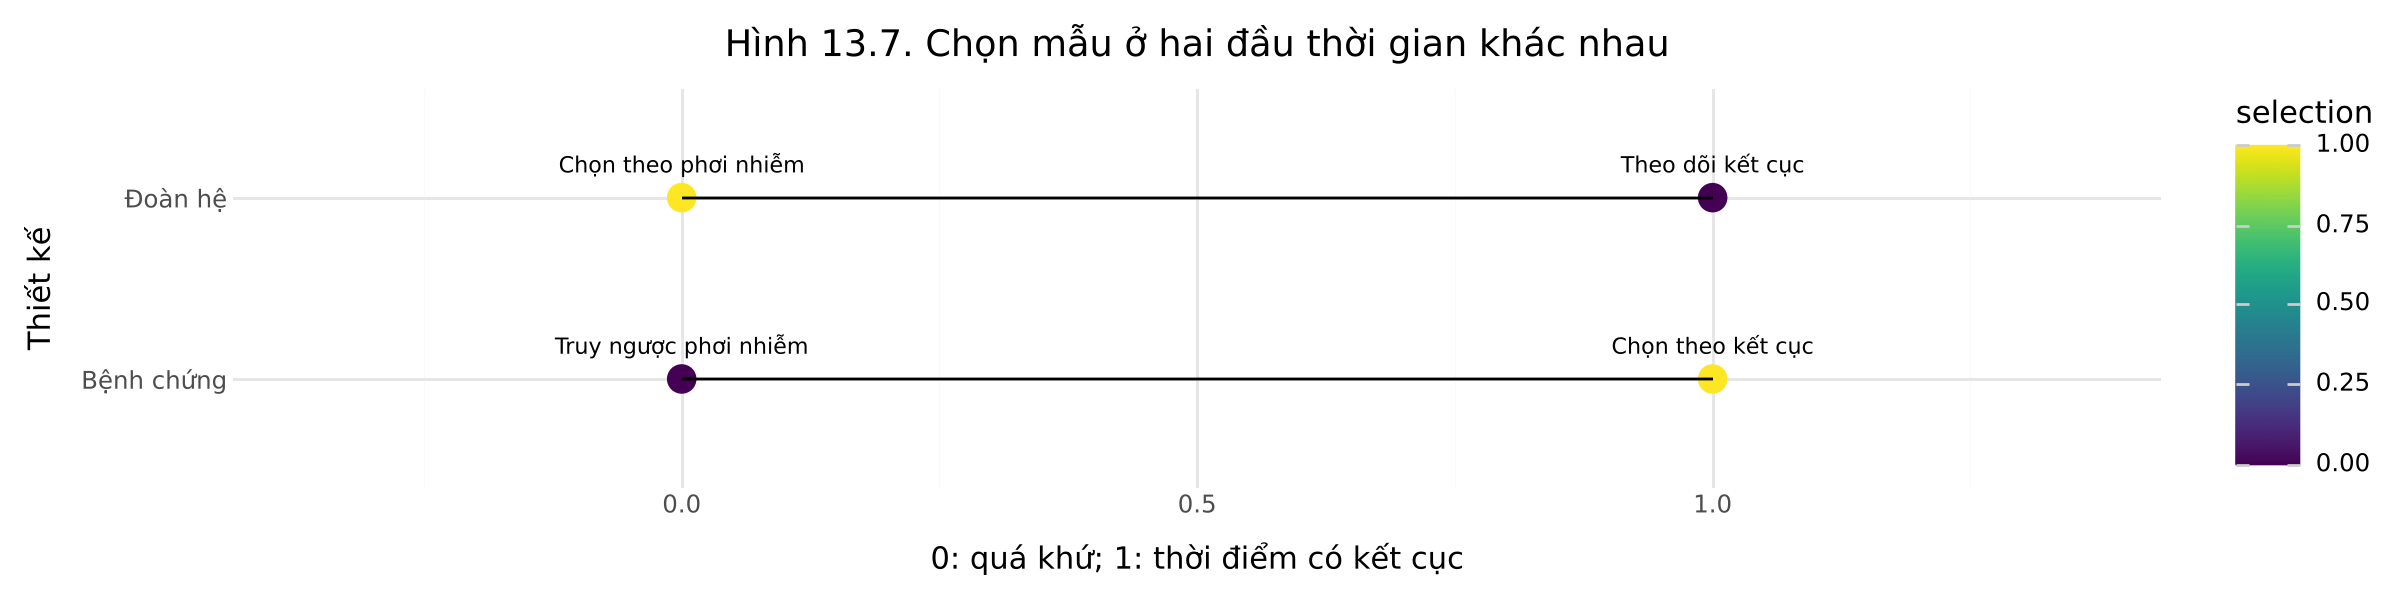

In [15]:
display(ggplot(study_time,aes('time','design',label='stage'))
    +geom_point(aes(color='selection'),size=5)+geom_text(nudge_y=.18,size=8)
    +geom_segment(aes(x=0,xend=1,y='design',yend='design'),inherit_aes=False)
    +coord_cartesian(xlim=(-.35,1.35))
    +labs(title='Hình 13.7. Chọn mẫu ở hai đầu thời gian khác nhau',x='0: quá khứ; 1: thời điểm có kết cục',y='Thiết kế')
    +theme_minimal()+theme(figure_size=(12,3)))

Sơ đồ chỉ thể hiện **trình tự** của hai thiết kế, không phải kết quả nghiên cứu nào.

### Câu hỏi 4 — Cỡ mẫu cho kết cục hiếm

Một kết cục xảy ra ở 2% tổng thể. (a) Nếu dùng thiết kế đoàn hệ và muốn quan sát trung bình khoảng 20 ca kết cục, cần theo dõi tối thiểu bao nhiêu người? (b) Vì sao thiết kế bệnh chứng tiết kiệm hơn cho kết cục hiếm?

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*(a)* Số ca kỳ vọng là $0{,}02\, n$. Cần $0{,}02\, n=20$, nên $n=20/0{,}02=1000$ người.

Đây là số **kỳ vọng**. Số ca thật là biến ngẫu nhiên $\operatorname{Binomial}(1000;\ 0{,}02)$ với độ lệch chuẩn $\sqrt{1000\times0{,}02\times0{,}98}\approx4{,}4$, nên có thể chỉ được 13 hay 15 ca. Muốn **chắc** có ít nhất 20 ca thì cần theo dõi nhiều hơn 1.000 người.

*(b)* Bệnh chứng chọn thẳng số ca bệnh cần thiết (ví dụ 20 ca từ hồ sơ bệnh viện) cùng một nhóm đối chứng không mắc bệnh, nên không phải theo dõi hàng nghìn người để chờ đủ ca. Cái giá: phải chọn đối chứng cẩn thận (họ phải đến từ cùng tổng thể với các ca), và việc nhớ lại phơi nhiễm trong quá khứ có thể không chính xác.

</details>

### Bài tập 3 — Thiết kế lại thí nghiệm (nâng cao)

Một công ty thử giao diện mới trên 6 lớp học online: 3 lớp dùng giao diện mới, 3 lớp dùng giao diện cũ. Các lớp dùng giao diện mới đều do giảng viên nhiều kinh nghiệm dạy. Chỉ số hiện tại là tỉ lệ nhấp nút “Bắt đầu”. Nêu ít nhất 2 lỗi thiết kế và đề xuất cách sửa để tăng hiệu lực nội tại.

<details><summary>Đáp án và cách lập luận — mở sau khi tự làm</summary>

*Lỗi 1: vi phạm nguyên tắc sai khác duy nhất.* Kinh nghiệm giảng viên khác nhau giữa hai nhóm, thay đổi cùng lúc với giao diện. *Sửa:* cân bằng giảng viên giữa hai nhóm; hoặc chia lớp thành khối theo giảng viên (hoặc theo mức kinh nghiệm) rồi gán giao diện ngẫu nhiên ở cấp lớp trong mỗi khối.

*Lỗi 2: chỉ số chưa bám mục tiêu học tập.* Tỉ lệ nhấp "Bắt đầu" chỉ đo việc bắt đầu, không đo việc học. *Sửa:* định trước một chỉ số như điểm kiểm tra cuối, tỉ lệ hoàn thành bài, hoặc tỉ lệ còn học sau 2 tuần.

*Lỗi 3 (nếu phân tích sai):* giao diện được gán theo **lớp**, nên đơn vị thí nghiệm là lớp; chỉ có 6 lần lặp. Không tính từng sinh viên hay từng lượt nhấp như lần lặp độc lập. Với 6 lớp, thí nghiệm có lực rất thấp; nên tăng số lớp nếu có thể.

</details>

<a id="muc-7"></a>

## 7. Bổ sung theo đề cương: đơn vị tương tự, nhiễu ẩn và thời gian

Phần này **bổ sung** theo đề cương (mục 4.4–4.5), không có trong slide tuần 13. Ba công cụ thường dùng với dữ liệu quan sát: ghép cặp, so sánh trước–sau, và khác biệt trong khác biệt.

### Ghép cặp (matching)

Ý tưởng: với mỗi người **đã nhận** can thiệp, tìm một người **chưa nhận** nhưng có biến nền gần giống, rồi dùng kết quả của người đó làm xấp xỉ cho phản thực. Ba nguyên tắc:

1. Chỉ ghép trên biến **trước** can thiệp. Không dùng kết quả sau can thiệp để chọn người ghép.
2. Kiểm tra cân bằng trước và sau ghép, và kiểm tra vùng chồng lấn (positivity, Tuần 12).
3. Ghép trên biến đã đo **không** loại trừ nhiễu ẩn từ biến chưa đo.

Nếu ghép mỗi người nhận với một đối chứng tương tự, đại lượng ước lượng gần với **ATT** (tác động trên nhóm đã nhận), không tự là ATE của cả tổng thể.

**Ví dụ.** Ô dưới ghép 5 sinh viên `cal_grad = True` trong bảng `grad_job` (Tuần 12) với 5 trong 15 sinh viên còn lại, dựa trên GPA và số năm kinh nghiệm.

- Hai biến được **chuẩn hóa** (trừ trung bình, chia độ lệch chuẩn) để cùng thang đo.
- `distance` là ma trận khoảng cách Euclid giữa mỗi người nhận và mỗi đối chứng.
- `linear_sum_assignment(distance)` chọn 5 cặp, mỗi đối chứng dùng tối đa một lần, sao cho **tổng** khoảng cách nhỏ nhất.

Ví dụ này đơn giản hóa: không dùng biến thư giới thiệu `rec`, và chỉ có 20 người; không cố tái tạo kết quả ghép nhiều biến của sách.

In [16]:
from scipy.optimize import linear_sum_assignment
grad=pd.read_csv(DATA/'grad_job.csv')
cov=['GPA','years_exp']
X=(grad[cov]-grad[cov].mean())/grad[cov].std(ddof=1)
it=grad.index[grad.cal_grad].to_numpy(); ic=grad.index[~grad.cal_grad].to_numpy()
distance=np.sqrt(((X.loc[it].to_numpy()[:,None,:]-X.loc[ic].to_numpy()[None,:,:])**2).sum(axis=2))
row,col=linear_sum_assignment(distance)
matched_t=grad.loc[it[row]].reset_index(drop=True)
matched_c=grad.loc[ic[col]].reset_index(drop=True)
pair_diff=matched_t.good_job.eq('yes').astype(int)-matched_c.good_job.eq('yes').astype(int)
display(pd.DataFrame({'treated_id':matched_t.id,'control_id':matched_c.id,'distance':distance[row,col],
    'job_difference':pair_diff}))
print('Hiệu thô:',grad.loc[it].good_job.eq('yes').mean()-grad.loc[ic].good_job.eq('yes').mean())
print('Hiệu sau ghép 2 biến:',pair_diff.mean())
balance=[]
for var in cov:
    denom=grad[var].std(ddof=1)
    balance.extend([[var,'Trước',(grad.loc[it,var].mean()-grad.loc[ic,var].mean())/denom],
                    [var,'Sau',(matched_t[var].mean()-matched_c[var].mean())/denom]])
balance_df=pd.DataFrame(balance,columns=['variable','stage','smd'])

,treated_id,control_id,distance,job_difference
0,4,17,0.22236,1
1,8,3,0.25015,0
2,11,16,0.30574,0
3,14,18,0.05559,0
4,15,9,0.08338,1


Hiệu thô: 0.33333333333333337
Hiệu sau ghép 2 biến: 0.4


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(balance_df, aes(...))` lấy bảng `balance_df`; trong `aes`, trục ngang là cột `smd`, trục đứng là cột `variable`. `color='stage'` cho mỗi giá trị của cột `stage` một màu riêng. `geom_point()` vẽ mỗi dòng của bảng thành một chấm. `geom_vline(xintercept=...)` vẽ đường đứt đoạn tại `0`.

**Đọc hình.** Trục ngang là **chênh lệch trung bình chuẩn hóa** (SMD): hiệu trung bình nhóm nhận − nhóm đối chứng, chia cho độ lệch chuẩn chung. Gần 0 là cân bằng. Với mỗi biến, so chấm “Trước” (toàn bộ 15 đối chứng) với chấm “Sau” (5 đối chứng đã ghép): chấm “Sau” gần đường 0 hơn.

<!-- branch-plot-instructions: end -->

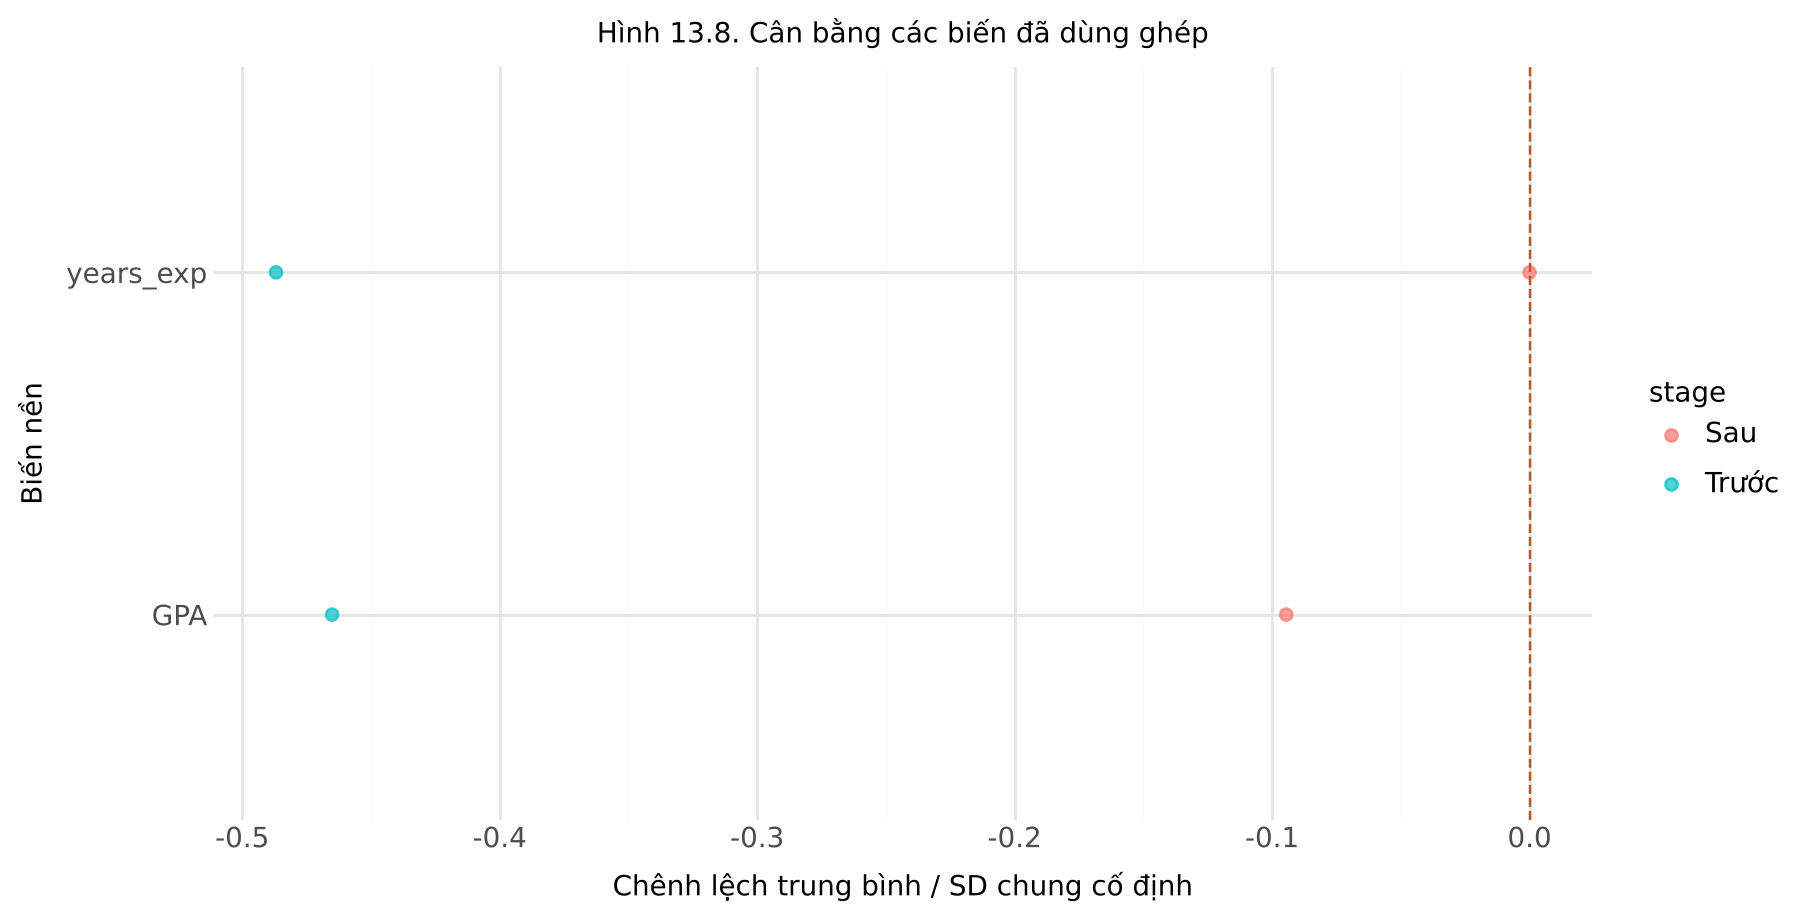

In [17]:
p = (ggplot(balance_df, aes(x='smd', y='variable', color='stage'))
     + geom_point(alpha=0.7, size=2)
     + geom_vline(xintercept=0, linetype='dashed', color='#C4512A')
     + labs(title='Hình 13.8. Cân bằng các biến đã dùng ghép', x='Chênh lệch trung bình / SD chung cố định', y='Biến nền')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

**Kết quả.** Hiệu thô là 0,333; sau ghép trên hai biến, hiệu trung bình trong 5 cặp là 0,4. Ghép làm hai nhóm giống nhau hơn về GPA và kinh nghiệm, và trong bảng nhỏ này hiệu lại tăng lên chứ không giảm. Không có quy luật nào nói ghép phải làm hiệu nhỏ đi.

Cân bằng tốt hai biến đã dùng không kiểm chứng được biến khác (thư giới thiệu, ngành học, hoàn cảnh gia đình) hay nhiễu ẩn. Với 5 cặp, ước lượng 0,4 dao động rất mạnh; bảng 20 người không đủ để kết luận gì về một trường đại học thật.

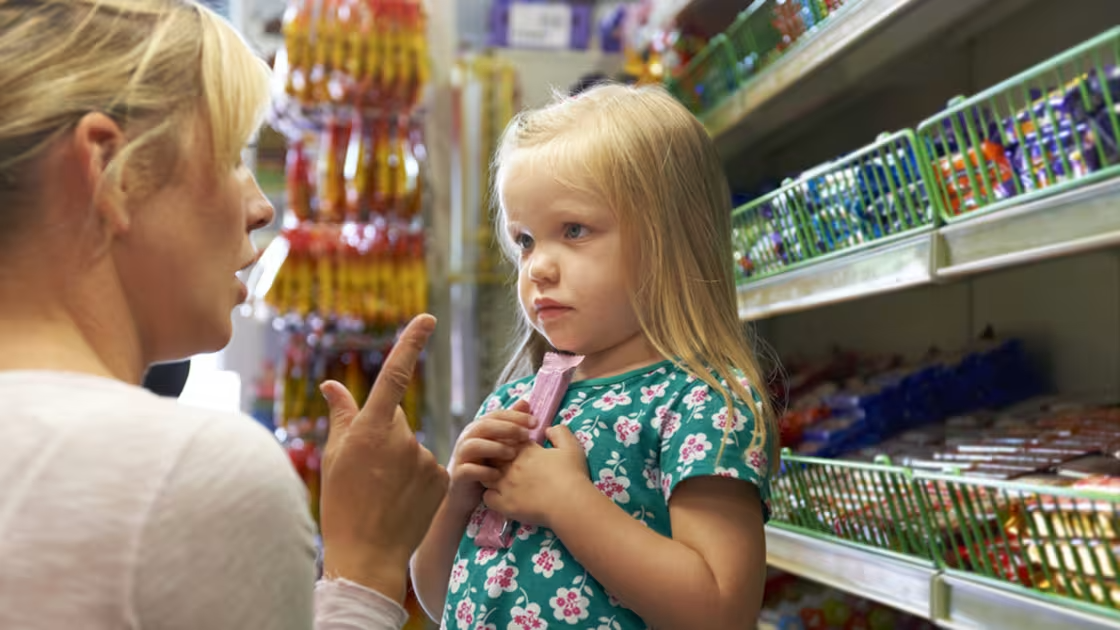

*Hình tham khảo 13.42: Quầy thanh toán trong tình huống chính sách siêu thị. Nguồn: STAT 20 bản dịch tiếng Việt, mục 6.4, hình nhúng trong học liệu gốc.*

Mục 6.4 của STAT 20: một chuỗi siêu thị bỏ đồ ăn vặt khỏi khu vực quầy thanh toán. Câu hỏi là lượng mua đồ ăn vặt có thay đổi không; kết cục sức khỏe không được đo trong dữ liệu này.

### Trước–sau trên cùng đơn vị

Bốn siêu thị được đo lượng bán gói thực phẩm không lành mạnh trước và sau chính sách. Đo hai lần trên **cùng** siêu thị giống dữ liệu ghép cặp ở Tuần 11: tính hiệu **sau − trước** cho từng siêu thị, rồi lấy trung bình. Cách này loại bỏ những đặc điểm cố định của từng siêu thị (quy mô, vị trí).

Nhưng sau − trước **không tự là** tác động của chính sách. Giữa hai lần đo, thời gian cũng trôi: mùa vụ, giá cả, khách hàng, quảng cáo đều có thể thay đổi. Không có nhóm đối chứng thì không tách được tác động chính sách khỏi những thay đổi đó.

Ô dưới tính hiệu từng siêu thị và một khoảng bootstrap **minh họa**. Bootstrap rút lại **cả siêu thị** (tức rút từ 4 hiệu), không rút riêng các dòng trước và sau, vì đơn vị là siêu thị (Tuần 10: giữ đúng cấu trúc). Với chỉ 4 cụm, khoảng bootstrap rất không đáng tin.

In [18]:
checkout=pd.read_csv(DATA/'checkout_prepost.csv')
checkout['difference']=checkout.post-checkout.pre
display(checkout)
print('Thay đổi trung bình:',checkout.difference.mean(),'gói')
checkout_long=checkout.melt(id_vars='store_id',value_vars=['pre','post'],var_name='period',value_name='sales')
checkout_long['time']=checkout_long.period.map({'pre':0,'post':1})
checkout_long['store']=checkout_long.store_id.astype(str)
boot_change=rng.choice(checkout.difference.to_numpy(),size=(5000,len(checkout)),replace=True).mean(axis=1)
print('Khoảng percentile minh họa, chỉ 4 cụm:',np.quantile(boot_change,[.025,.975]))

,store_id,pre,post,difference
0,243,4585,2455,-2130
1,245,6221,4344,-1877
2,246,1991,3341,1350
3,247,2347,2271,-76


Thay đổi trung bình: -683.25 gói
Khoảng percentile minh họa, chỉ 4 cụm: [-2003.5   637. ]


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(checkout_long, aes(...))` lấy bảng `checkout_long`; trong `aes`, trục ngang là cột `time`, trục đứng là cột `sales`. `color='store'` cho mỗi giá trị của cột `store` một màu riêng. `geom_line()` nối các điểm theo thứ tự tăng dần của trục ngang.

**Đọc hình.** Mỗi đường nối hai lần đo của **một** siêu thị. Ba đường đi xuống (243, 245 giảm mạnh, 247 giảm ít), một đường đi lên (246). Độ dốc mỗi đường chính là cột `difference` trong bảng.

<!-- branch-plot-instructions: end -->

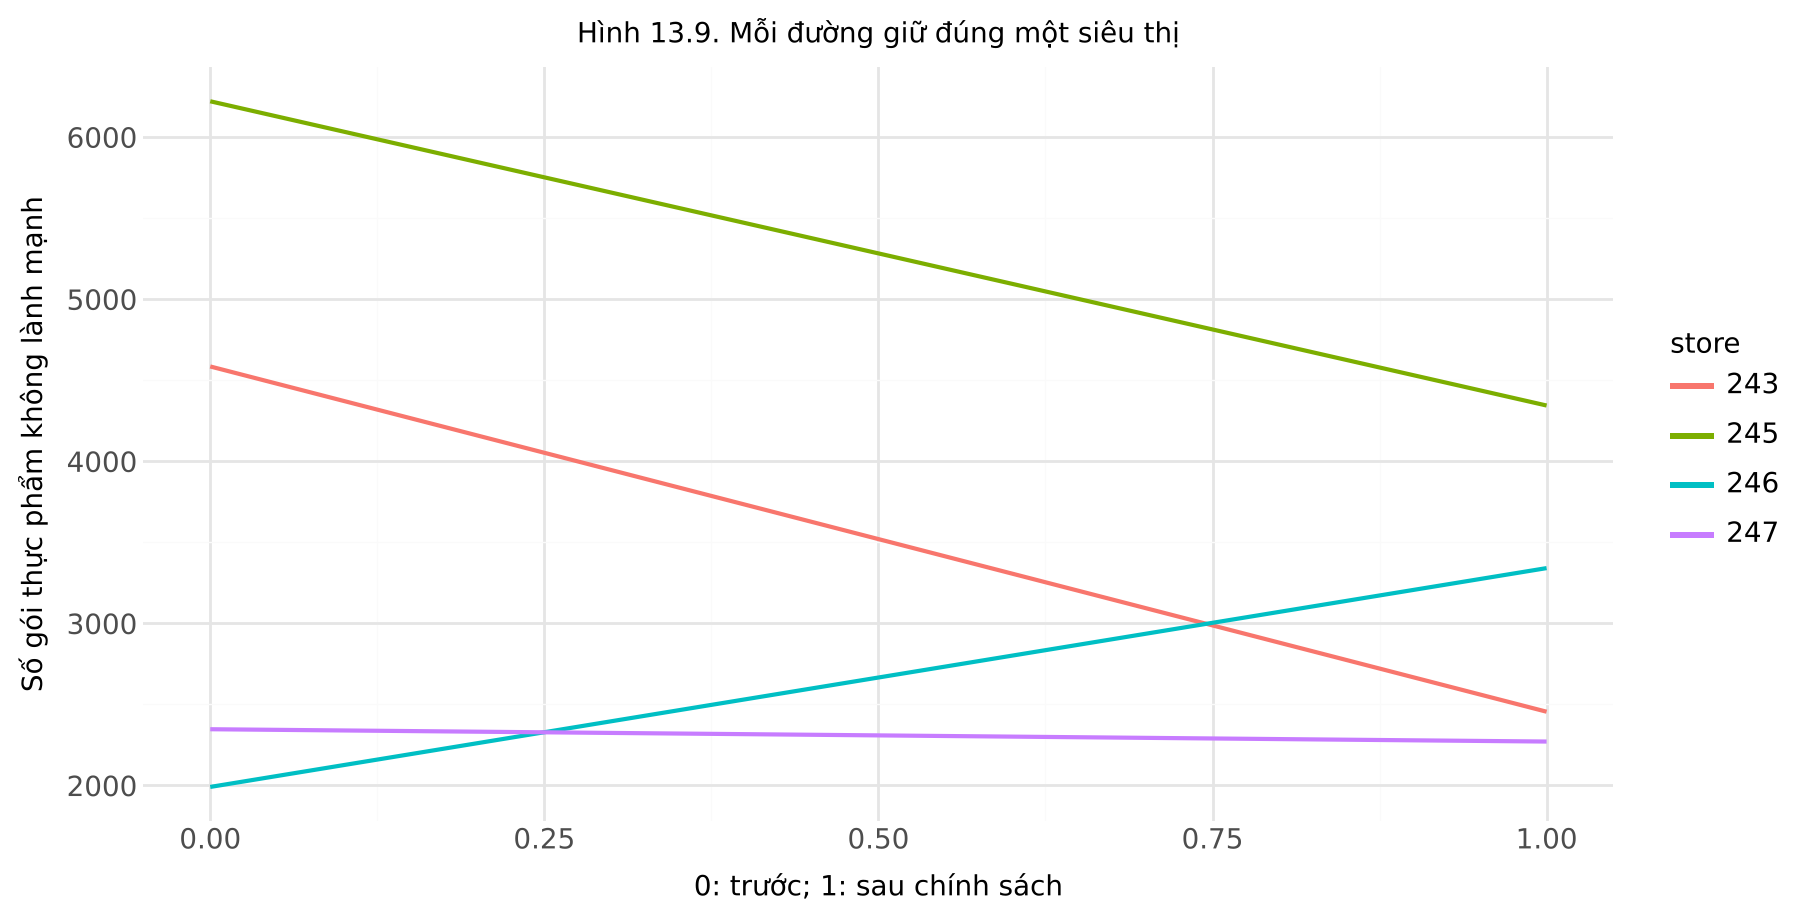

In [19]:
p = (ggplot(checkout_long, aes(x='time', y='sales', color='store'))
     + geom_line(size=0.85)
     + labs(title='Hình 13.9. Mỗi đường giữ đúng một siêu thị', x='0: trước; 1: sau chính sách', y='Số gói thực phẩm không lành mạnh')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

**Kết quả.** Thay đổi trung bình là $-683{,}25$ gói, nhưng ba siêu thị giảm và một siêu thị tăng 1.350 gói. Khoảng bootstrap từ khoảng $-2000$ đến $+640$ chứa cả số âm lẫn số dương. Giữ đúng cặp là điều kiện để tính đúng; nó chưa giải quyết được xu hướng thời gian.

### Khác biệt trong khác biệt (DiD) và chuỗi thời gian bị gián đoạn (ITS)

Nếu có thêm một **nhóm đối chứng** không chịu chính sách, đo cùng hai kỳ:
$$\text{DiD}=\big(\text{sau}-\text{trước}\big)_{\text{can thiệp}}-\big(\text{sau}-\text{trước}\big)_{\text{đối chứng}}.$$
Đọc là: thay đổi ở nhóm đối chứng ước lượng "điều gì sẽ xảy ra theo thời gian nếu không có chính sách"; trừ nó khỏi thay đổi ở nhóm can thiệp để giữ lại phần do chính sách.

Giả định then chốt: **xu hướng phản thực song song**. Nếu không có chính sách, hai nhóm sẽ thay đổi cùng một mức. Thêm: không có cú sốc nào khác chỉ xảy ra ở một nhóm đúng lúc đó, và thành phần mỗi nhóm đủ ổn định. Chỉ có một kỳ đo trước thì không kiểm tra được xu hướng song song; cần nhiều kỳ trước để thấy hai nhóm có đi cùng nhau không.

**ITS** dùng nhiều kỳ đo trước và sau một mốc để mô hình hóa xu hướng, rồi ước lượng chính sách làm **dịch mức** (bước nhảy) hay **đổi độ dốc** bao nhiêu. Giả định: không có thay đổi nào khác xảy ra đúng mốc đó, và mô hình xu hướng hợp lý; mùa vụ và tương quan giữa các kỳ liên tiếp cần được xử lý.
<details><summary><b>Vì sao?</b> DiD loại bỏ xu hướng chung</summary>

Viết lượng bán trung bình của nhóm $g$ ở kỳ $t$ là
$$\bar Y_{g, t}=a_g+b_t+\delta\cdot\mathbb 1[g=\text{can thiệp},\ t=\text{sau}],$$
với $a_g$ là mức riêng của nhóm (cố định theo thời gian), $b_t$ là xu hướng **chung** cho cả hai nhóm, và $\delta$ là tác động chính sách.

Thay đổi ở nhóm can thiệp: $(b_{\text{sau}}-b_{\text{trước}})+\delta$. Thay đổi ở nhóm đối chứng: $b_{\text{sau}}-b_{\text{trước}}$. Trừ hai thay đổi, cả $a_g$ lẫn xu hướng chung $b_t$ biến mất:
$$\text{DiD}=\delta.\ \blacksquare$$
Chữ "chung" là giả định xu hướng song song. Nếu nhóm can thiệp có xu hướng riêng $b'_t$ khác $b_t$, DiD bằng $\delta+(b'_{\text{sau}}-b'_{\text{trước}})-(b_{\text{sau}}-b_{\text{trước}})$: lẫn tác động với chênh lệch xu hướng.

</details>

**Mô phỏng.** Ô dưới dựng 12 kỳ cho hai nhóm, **không có nhiễu**, để thấy rõ cơ chế:

- cả hai nhóm có cùng xu hướng giảm 2 đơn vị mỗi kỳ; nhóm can thiệp bắt đầu ở 100, nhóm đối chứng ở 80;
- chính sách từ kỳ 6 làm nhóm can thiệp giảm thêm 4 đơn vị.

Ô tính thay đổi trung bình trước/sau của từng nhóm, DiD, và một mô hình ITS cho riêng nhóm can thiệp: `smf.ols('sales ~ time + post_num', ...)` khớp một đường thẳng theo thời gian cộng một bước nhảy tại kỳ 6; hệ số `post_num` là bước nhảy ước lượng.

In [20]:
time=np.arange(12)
panel=pd.concat([pd.DataFrame({'time':time,'group':g,
    'sales':base-2*time+np.where((time>=6)&(g=='Can thiệp'),-4,0)})
    for g,base in [('Can thiệp',100),('Đối chứng',80)]],ignore_index=True)
panel['post']=panel.time>=6
means=panel.groupby(['group','post']).sales.mean().unstack()
changes=means[True]-means[False]
print('Hiệu trước–sau:',changes.to_dict(),'; DiD:',changes['Can thiệp']-changes['Đối chứng'])
# ITS: biến thời gian + post cho dịch mức; thêm time_after nếu xét đổi độ dốc.
treated=panel[panel.group=='Can thiệp'].copy()
treated['post_num']=treated.post.astype(int)
its=smf.ols('sales ~ time + post_num',treated).fit()
print('ITS, hệ số dịch mức:',its.params['post_num'])

Hiệu trước–sau: {'Can thiệp': -16.0, 'Đối chứng': -12.0} ; DiD: -4.0
ITS, hệ số dịch mức: -3.999999999999986


<!-- branch-plot-instructions: start -->

**Đọc code vẽ bằng Plotnine.** `ggplot(panel, aes(...))` lấy bảng `panel`; trong `aes`, trục ngang là cột `time`, trục đứng là cột `sales`. `color='group'` cho mỗi giá trị của cột `group` một màu riêng. `geom_line()` nối các điểm theo thứ tự tăng dần của trục ngang. `geom_vline(xintercept=...)` vẽ đường đứt đoạn tại `6`.

**Đọc hình.** Hai đường song song trước kỳ 6 (cùng dốc −2). Tại đường đứt đoạn (kỳ 6), đường “Can thiệp” tụt thêm một bậc 4 đơn vị rồi lại song song với đường “Đối chứng”. Khoảng cách giữa hai đường tăng từ 20 lên 24: đó chính là DiD.

<!-- branch-plot-instructions: end -->

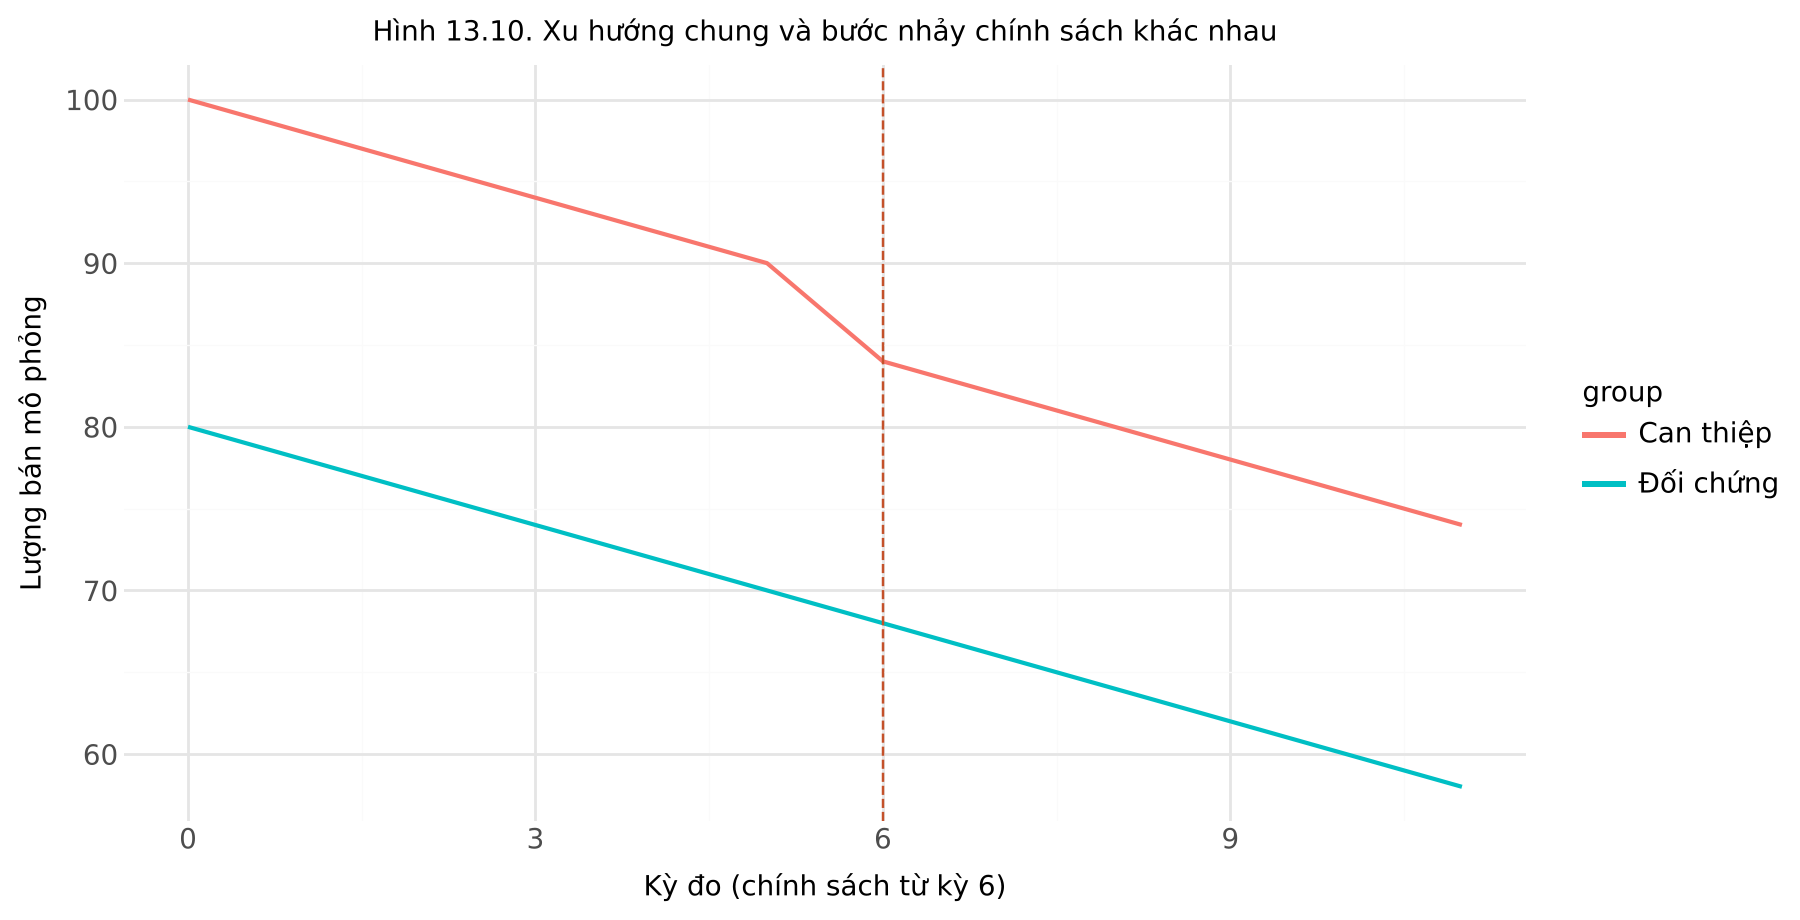

In [21]:
p = (ggplot(panel, aes(x='time', y='sales', color='group'))
     + geom_line(size=0.85)
     + geom_vline(xintercept=6, linetype='dashed', color='#C4512A')
     + labs(title='Hình 13.10. Xu hướng chung và bước nhảy chính sách khác nhau', x='Kỳ đo (chính sách từ kỳ 6)', y='Lượng bán mô phỏng')
     + theme_minimal()
     + theme(figure_size=(9, 4.6), text=element_text(size=10)))
display(p)

**Kết quả.** Nhóm can thiệp giảm 16 đơn vị giữa trung bình trước và sau, nhóm đối chứng giảm 12 (chỉ do xu hướng: 6 kỳ × 2). So sánh trước–sau đơn thuần sẽ báo tác động $-16$; DiD cho $-16-(-12)=-4$, đúng giá trị đã đặt. Mô hình ITS cũng khôi phục bước nhảy $-4$.

**Thử đổi.** Trong ô trên, sửa độ dốc của nhóm can thiệp thành −3 (thay `base-2*time` bằng một độ dốc riêng cho nhóm can thiệp). Khi đó hai nhóm không còn song song; DiD sẽ lẫn tác động với chênh lệch xu hướng, đúng như khối **Vì sao?** đã chỉ ra.

## Tóm tắt và lỗi hay gặp

| Ý chính | Lỗi hay gặp |
|---|---|
| Hiệu lực nội tại (so sánh có cô lập đúng tác động không) và khái quát (áp dụng ngoài mẫu được không) là hai trục riêng. | Nghĩ mẫu lớn hay đại diện thì so sánh tự đúng. |
| Lấy mẫu ngẫu nhiên phục vụ khái quát; gán ngẫu nhiên phục vụ nội tại. | Lẫn hai loại “ngẫu nhiên”. |
| Đơn vị thí nghiệm là cấp được gán độc lập; đơn vị quan sát là cấp được đo. | Đếm học sinh, gà, lượt nhấp như lần lặp độc lập khi gán theo trường, chuồng, người dùng. |
| Đếm nhầm đơn vị thổi phồng cỡ mẫu, SE quá nhỏ, báo động giả tăng mạnh (5% → 55%). | Tăng số quan sát mỗi cụm thay vì tăng số cụm. |
| RCT: biến kết quả định trước, đối chứng, gán ngẫu nhiên, cùng quy trình đo. | Chia nhóm “tùy tiện” rồi gọi là RCT. |
| Sai khác duy nhất: chỉ nghiệm thức được khác giữa các nhóm. | Cho nhóm nghiệm thức thêm thời gian, thợ giỏi hơn, máy mới hơn. |
| Khối: gán **trong** mỗi khối, giảm dao động; cụm: gán **cả** cụm. Phân tích phải giữ thiết kế. | Phân tích dữ liệu khối hoặc cụm như gán hoàn toàn cá thể. |
| A/B là RCT; chỉ số chính phải bám mục tiêu thật và định trước. | Đổi chỉ số sau khi xem dữ liệu. |
| Thiết kế quan sát (tự nhiên, đoàn hệ, bệnh chứng, ghép cặp, DiD) cần biện luận giả định. | Coi trước–sau là tác động; coi ghép trên biến đã đo là đã hết nhiễu. |

## Tự kiểm tra và nối sang buổi tiếp theo

1. Chọn một nghiên cứu bạn quan tâm và viết bốn câu: đơn vị được gán và đơn vị được đo; đối chứng và biến kết quả; cơ chế nào làm phép so sánh đáng tin; giả định nào vẫn có thể sai.
2. Vì sao hàng triệu dòng dữ liệu không thay được việc có đủ đơn vị gán độc lập?
3. Một thí nghiệm gán thuốc theo bệnh viện: 10 bệnh viện, mỗi bệnh viện 200 bệnh nhân. Có bao nhiêu lần lặp độc lập?
4. Trong DiD, nếu nhóm đối chứng là các siêu thị ở một thành phố vừa có lễ hội lớn đúng tháng sau chính sách, giả định nào bị đe dọa?

<details><summary>Gợi ý đáp án</summary>

2. Độ chính xác bị giới hạn bởi số đơn vị gán, không phải số dòng. Với mẫu cụm, thêm dòng trong cùng cụm chỉ giảm phần phương sai do cá thể; phần phương sai do cụm vẫn nguyên (khối **Vì sao?** ở mục 2).
3. 10.
4. Giả định không có cú sốc riêng một nhóm (và xu hướng song song): lễ hội làm lượng bán của nhóm đối chứng thay đổi vì lý do khác chính sách.

</details>

**Buổi sau.** Tuần 14 chuyển mục tiêu từ **giải thích** sang **dự đoán**. Một mô hình có thể dự đoán rất tốt mà các hệ số của nó vẫn không có nghĩa nhân quả. Buổi sau học: hồi quy tuyến tính và cách khớp (OLS, gradient descent), kiểm định hệ số, các thước đo sai số dự đoán, phân tích phần dư, đa cộng tuyến và chọn biến.

## Nguồn học liệu

- Slide của học phần: `week13.pdf`; số trang được ghi trong metadata `source_pages` của từng ô.
- Đề cương UET.MAT1052: mục và chuẩn đầu ra của tuần tương ứng.
- STAT 20 bản dịch tiếng Việt: mục 6.2–6.4. Các hình tham khảo được nhúng thẳng vào notebook.
- Dữ liệu và cách chuyển đổi: `datasets/W09_W15_SOURCE_MANIFEST.json` và [hướng dẫn tuần 09–15](./README_W09_W15.md). Dữ liệu OpenIntro lấy từ [kho dữ liệu của nhà xuất bản](https://www.openintro.org/data/).